# Семинар 3: Классификация изображений

Сегодня переходим к более сложным изображениям и архитектурам.

### План семинара
1. Обучаем CNN на CIFAR-10; разбираем веса и активации в цвете и числах, затем Grad-CAM: «куда смотрят свёртки».
2. Экспериментируем с активациями и аугментациями.
3. Изучаем регуляризацию и нормализацию.

In [ ]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from IPython.display import clear_output
from torch import nn, optim
from torchvision import transforms
from tqdm.auto import tqdm
import time


warnings.filterwarnings("ignore")
%matplotlib inline

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

## 1. Обучаем свёрточную сеть для задачи классификации изображений

Сегодня будем работать с датасетом [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html), в котором содержатся изображения 10 (airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck) классов размером 32 на 32 пикселя с тремя каналами. В тренировочной выборке 50000 изображений, а в тестовой 10000. Загрузим его аналогично тому, как мы загружали MNIST на предыдущих занятиях.

Напоминание про форматы хранения изображений в разных библиотеках, с которыми мы работаем

В PyTorch тензоры изображений обычно имеют вид:
[batch, channels, height, width] — то есть, NCHW,
либо [channels, height, width] для одной картинки

В numpy и matplotlib изображения часто имеют вид:
[height, width, channels] — то есть, HWC

Поэтому мы часто используем np.transpose(npimg, (1, 2, 0)) для массивов numpy и img.permute(1, 2, 0) в PyTorch

In [ ]:
transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261)), # каналов 3, поэтому и чисел теперь по 3
    ]
)

cifar_train = torchvision.datasets.CIFAR10(
    root="./cifar", train=True, download=True, transform=transform
)
cifar_val = torchvision.datasets.CIFAR10(
    root="./cifar", train=False, download=True, transform=transform
)

train_dataloader = torch.utils.data.DataLoader(
    cifar_train, batch_size=32, shuffle=True, num_workers=4
)
val_dataloader = torch.utils.data.DataLoader(
    cifar_val, batch_size=32, shuffle=False, num_workers=4
)

In [ ]:
def matplotlib_imshow(img, one_channel=False):
    # Обратное преобразование для Normalize из этого семинара.
    img = img.detach().cpu()
    mean = img.new_tensor([0.4914, 0.4822, 0.4465])[:, None, None]
    std = img.new_tensor([0.247, 0.243, 0.261])[:, None, None]
    rgb = (img * std + mean).clamp(0, 1)
    if one_channel:
        plt.imshow(rgb.mean(dim=0).numpy(), cmap="gray", vmin=0, vmax=1)
    else:
        plt.imshow(rgb.permute(1, 2, 0).numpy())

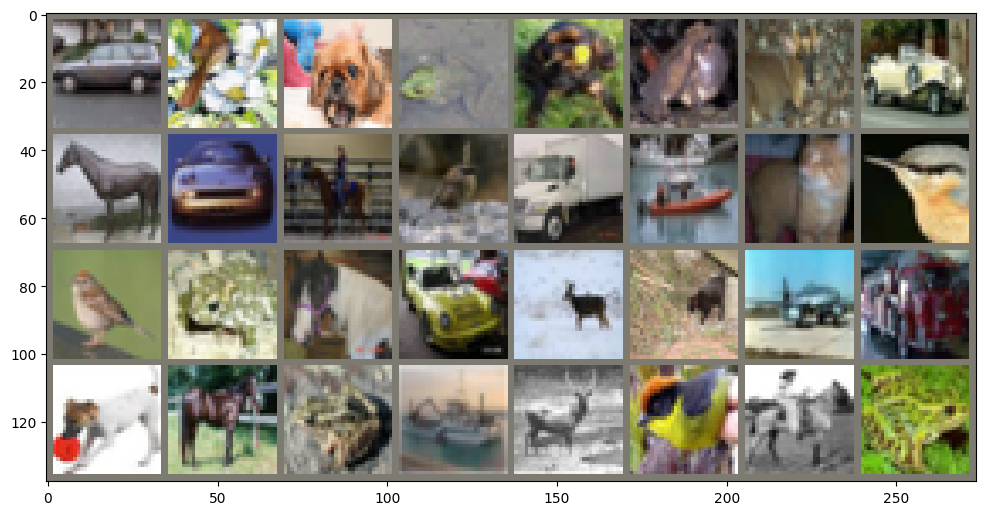

In [ ]:
images, labels = next(iter(train_dataloader))

plt.figure(figsize=(12, 12))
# create grid of images
img_grid = torchvision.utils.make_grid(images)
# show images
matplotlib_imshow(img_grid, one_channel=False)

In [ ]:
def plot_history(train_history, val_history, title="loss"):
    plt.figure()
    plt.title(title)
    plt.plot(train_history, label="train", zorder=1)

    points = np.array(val_history)
    steps = list(
        range(0, len(train_history) + 1, int(len(train_history) / len(val_history)))
    )[1:]

    plt.scatter(
        steps, val_history, marker="+", s=180, c="orange", label="val", zorder=2
    )
    plt.xlabel("train steps")

    plt.legend(loc="best")
    plt.grid()

    plt.show()

In [ ]:
def plot_time(time_log):
    plt.figure()
    plt.title("Epoch time (seconds)")
    plt.plot(range(1, len(time_log) + 1), time_log, marker="o", c="red")
    plt.xlabel("Epoch")
    plt.ylabel("Time, sec")
    plt.grid()
    plt.show()

### Задание 1. VGG
В качестве бейзлайна постройте следующую архитектуру из 1 VGG блока:

1) VGG блок с 16 каналами:
* свёрточный слой с 16 выходными каналами и ядром 3x3, паддингом и нелинейностью ReLU
* свёрточный слой с 16 выходными каналами и ядром 3x3, паддингом и нелинейностью ReLU
* Max pooling c ядром 2x2 и шагом 2

2) Полносвязный слой с 128 выходами и нелинейностью ReLU

3) Полносвязный слой с 10 выходами

In [ ]:
class ModelBaseline(nn.Module):
    def __init__(self):
        super(ModelBaseline, self).__init__()

        self.model = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size= (3, 3), padding='same'),
            nn.ReLU(),
            nn.Conv2d(in_channels=16, out_channels=16, kernel_size= (3, 3), padding='same'),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 2), stride=2),
            nn.Flatten(),
            nn.Linear(in_features=16 * 16 * 16, out_features=128),
            nn.ReLU(),
            nn.Linear(in_features=128, out_features=10)
        )


    def forward(self, x):
        return self.model(x)

In [ ]:
# @title
class ModelBaseline(nn.Module):
    def __init__(self):
        super(ModelBaseline, self).__init__()

        self.vgg = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding = 'same'),
            nn.ReLU(),
            nn.Conv2d(16, 16, kernel_size=3, padding = 'same'),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Полносвязные слои
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 16 * 16, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.vgg(x)
        x = self.fc(x)
        return x

In [ ]:
def train(model, criterion, optimizer, train_dataloader, val_dataloader, n_epochs=5):
    """criterion возвращает средний loss по батчу (reduction='mean')."""
    history = {key: [] for key in ("train_loss", "train_acc", "val_loss", "val_acc", "time")}
    model_device = next(model.parameters()).device

    for epoch in range(n_epochs):
        epoch_start = time.time()
        model.train()
        train_loss_sum, train_hits, train_count = 0.0, 0, 0
        for imgs, labels in tqdm(train_dataloader, desc=f"Training, epoch {epoch+1}", leave=False):
            imgs, labels = imgs.to(model_device), labels.to(model_device)
            optimizer.zero_grad()
            logits = model(imgs)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)
            hits = (logits.argmax(dim=1) == labels).sum().item()
            # loss уже усреднён; для среднего по эпохе учитываем размер батча.
            train_loss_sum += loss.item() * batch_size
            train_hits += hits
            train_count += batch_size
            history["train_loss"].append(loss.item())
            history["train_acc"].append(hits / batch_size)

        model.eval()
        val_loss_sum, val_hits, val_count = 0.0, 0, 0
        with torch.no_grad():
            for imgs, labels in tqdm(val_dataloader, desc=f"Validating, epoch {epoch+1}", leave=False):
                imgs, labels = imgs.to(model_device), labels.to(model_device)
                logits = model(imgs)
                batch_size = labels.size(0)
                val_loss_sum += criterion(logits, labels).item() * batch_size
                val_hits += (logits.argmax(dim=1) == labels).sum().item()
                val_count += batch_size

        history["val_loss"].append(val_loss_sum / val_count)
        history["val_acc"].append(val_hits / val_count)
        history["time"].append(time.time() - epoch_start)
        clear_output()
        plot_history(history["train_loss"], history["val_loss"], "loss")
        plot_history(history["train_acc"], history["val_acc"], "accuracy")
        plot_time(history["time"])
        print(f"Epoch {epoch+1}/{n_epochs}")
        print(f"Train loss: {train_loss_sum / train_count:.6f}")
        print(f"Train acc: {train_hits / train_count:.6f}")
        print(f"Val loss: {history['val_loss'][-1]:.6f}")
        print(f"Val acc: {history['val_acc'][-1]:.6f}")
        print(f"Epoch time: {history['time'][-1]:.2f} sec")

    return history

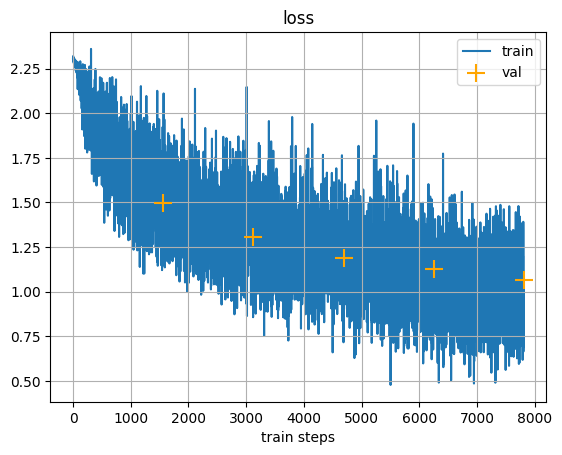

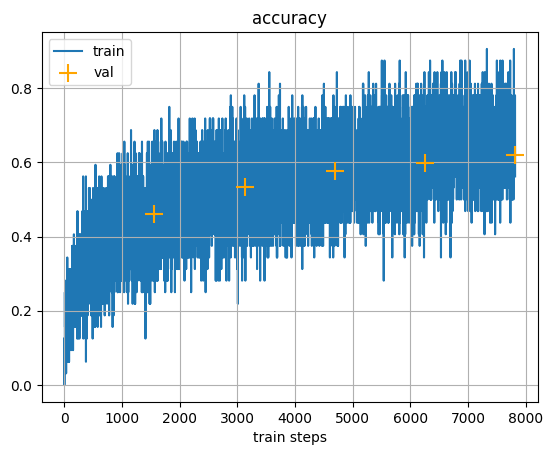

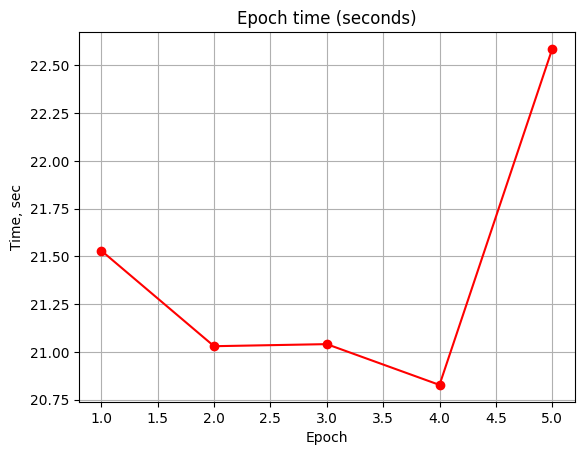

Epoch 5/5
Train loss: 1.000563
Train acc: 0.647700
Val loss: 1.068294
Val acc: 0.621400
Epoch time: 22.59 sec


In [ ]:
model_baseline = ModelBaseline().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model_baseline.parameters(), lr=0.001, momentum=0.9)

train(model_baseline, criterion, optimizer, train_dataloader, val_dataloader);

### Визуализации: от чисел в свёртке к решению сети

Запускайте после обучения baseline, до замены ReLU. Используем ту же модель и CIFAR-10, без внешнего `filter_viz.py`.

#### 1. Веса свёрток: цвет и числа

Веса первого слоя `[16, 3, 3, 3]` — это 16 фильтров по три матрицы 3×3 для R, G и B. Их вклады суммируются; bias добавляется один раз на выходной канал.

Красный — положительный вес, синий — отрицательный, белый — ноль. Подписи и цвет соответствуют одним числам; округлены только подписи. Это параметры сети, не RGB-интенсивности. Во втором слое входы уже являются признаками.

Покажем четыре фильтра первого слоя и все 16 входных каналов одного фильтра второго. Выбор: `channels` и `second_filter`.

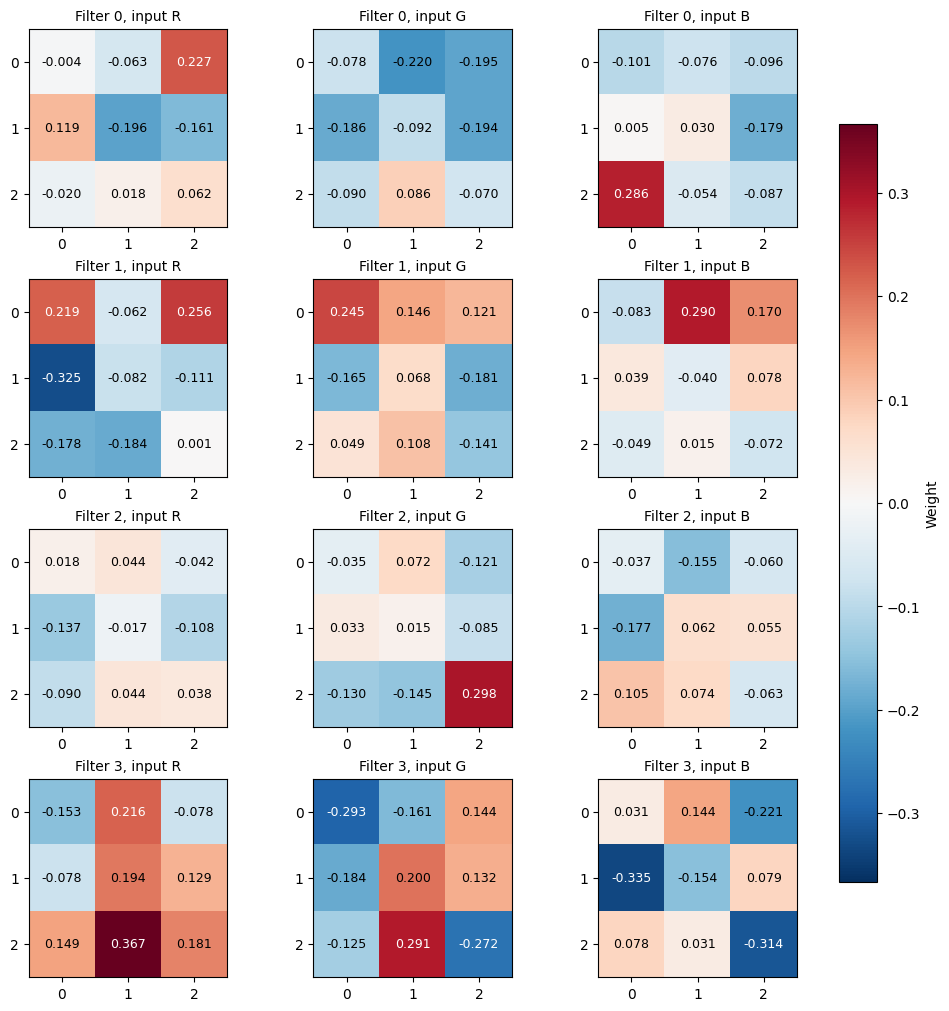

Bias первого слоя для выбранных фильтров:
tensor([-0.1742,  0.1282,  0.2846,  0.2024])


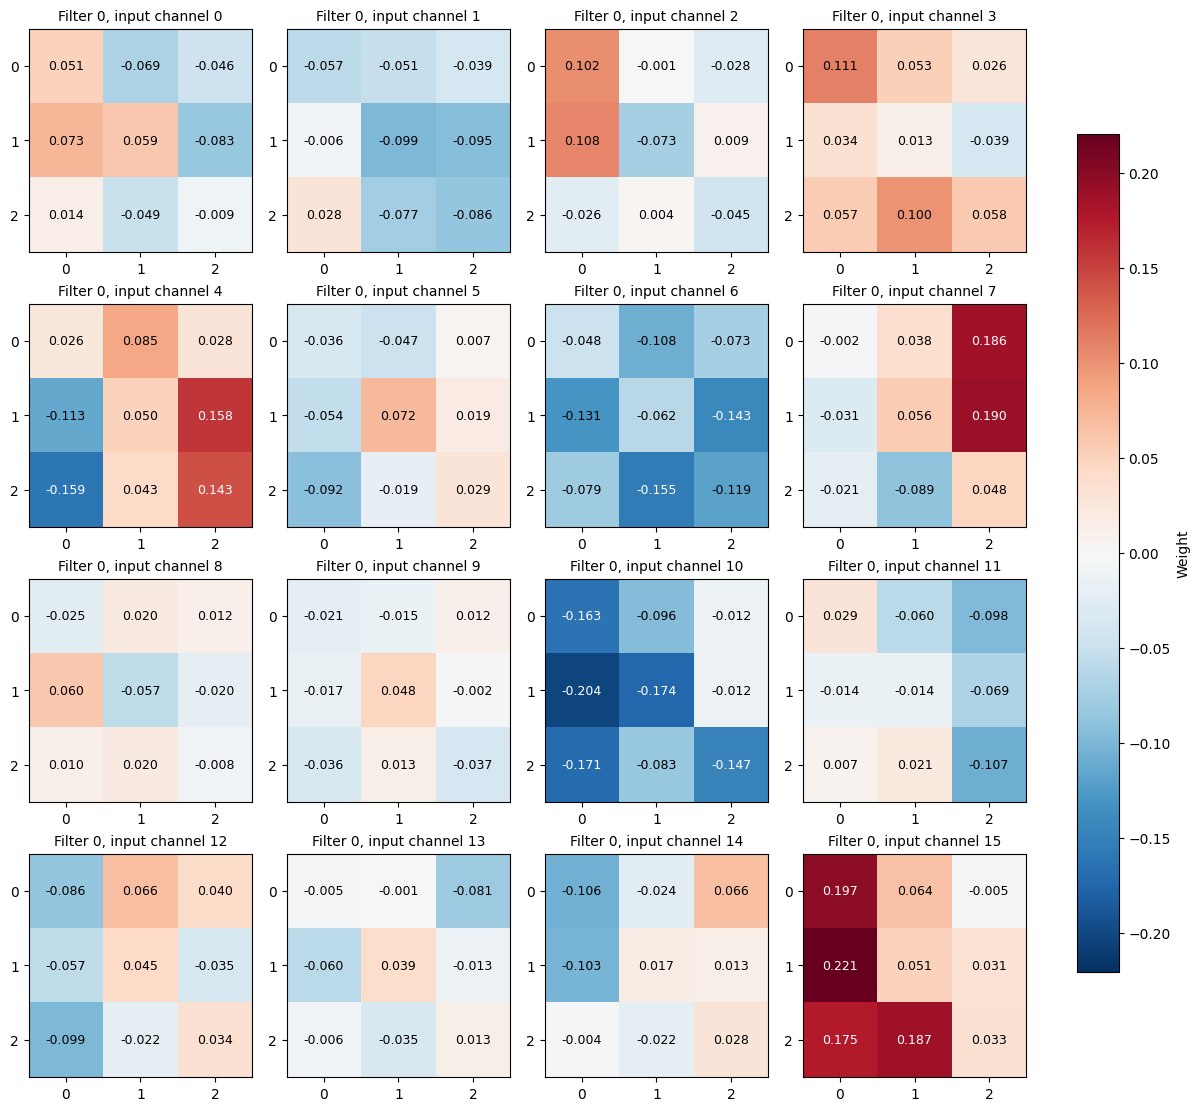

Bias выбранного фильтра второго слоя: 0.10158050805330276


In [ ]:
from matplotlib.patches import Rectangle

# Поддерживаем обе записи архитектуры из задания 1.
feature_layers = (model_baseline.vgg if hasattr(model_baseline, "vgg")
                  else model_baseline.model)
expected = (nn.Conv2d, nn.ReLU, nn.Conv2d, nn.ReLU, nn.MaxPool2d)
assert len(feature_layers) >= 5 and all(
    isinstance(layer, kind) for layer, kind in zip(feature_layers[:5], expected)
), "Сначала обучите базовую CNN с ReLU из задания 1."


def matrix_with_numbers(ax, matrix, title, *, vmin=None, vmax=None,
                        cmap="RdBu_r", fmt=".3f", row0=0, col0=0):
    """Цвет и подпись берём из одного массива, без изменения его значений."""
    values = torch.as_tensor(matrix).detach().cpu().numpy()
    im = ax.imshow(values, cmap=cmap, vmin=vmin, vmax=vmax,
                   interpolation="nearest")
    for (i, j), value in np.ndenumerate(values):
        red, green, blue, _ = im.cmap(im.norm(value))
        luminance = 0.2126 * red + 0.7152 * green + 0.0722 * blue
        ax.text(j, i, format(float(value), fmt), ha="center", va="center",
                fontsize=9, color="black" if luminance > 0.5 else "white")
    ax.set_xticks(range(values.shape[1]), range(col0, col0 + values.shape[1]))
    ax.set_yticks(range(values.shape[0]), range(row0, row0 + values.shape[0]))
    ax.set_title(title, fontsize=10)
    return im


channels = [0, 1, 2, 3]
weights = feature_layers[0].weight.detach().cpu()
limit = max(weights[channels].abs().max().item(), 1e-8)
fig, axes = plt.subplots(len(channels), 3, figsize=(10, 10),
                         squeeze=False, constrained_layout=True)
for row, channel in enumerate(channels):
    for c, color in enumerate(["R", "G", "B"]):
        im = matrix_with_numbers(axes[row, c], weights[channel, c],
                                 f"Filter {channel}, input {color}",
                                 vmin=-limit, vmax=limit)
fig.colorbar(im, ax=axes.ravel().tolist(), label="Weight", shrink=0.8)
plt.show()
print("Bias первого слоя для выбранных фильтров:")
print(feature_layers[0].bias.detach().cpu()[channels])

second_filter = 0
weights2 = feature_layers[2].weight.detach().cpu()[second_filter]
limit = max(weights2.abs().max().item(), 1e-8)
fig, axes = plt.subplots(4, 4, figsize=(12, 11), constrained_layout=True)
for c, ax in enumerate(axes.flat):
    im = matrix_with_numbers(ax, weights2[c],
                             f"Filter {second_filter}, input channel {c}",
                             vmin=-limit, vmax=limit)
fig.colorbar(im, ax=axes.ravel().tolist(), label="Weight", shrink=0.8)
plt.show()
print("Bias выбранного фильтра второго слоя:",
      feature_layers[2].bias[second_filter].item())

#### 2. От фильтра к карте активаций

Веса фиксированы, а активации зависят от картинки. Снимем выходы `Conv 1 → ReLU 1 → Conv 2 → ReLU 2 → MaxPool`.

Рядом с полной картой показываем обведённый фрагмент 4×4 с числами на той же шкале. Координаты — строка и столбец, с нуля. Полные матрицы доступны в `conv1[channel]`, `relu1[channel]` и аналогично для других этапов.

ReLU действует поэлементно: $a_{kij}=\max(0,z_{kij})$; форма тензора не меняется.

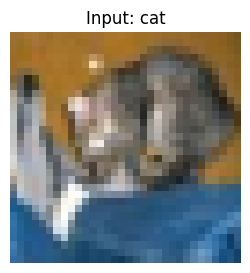

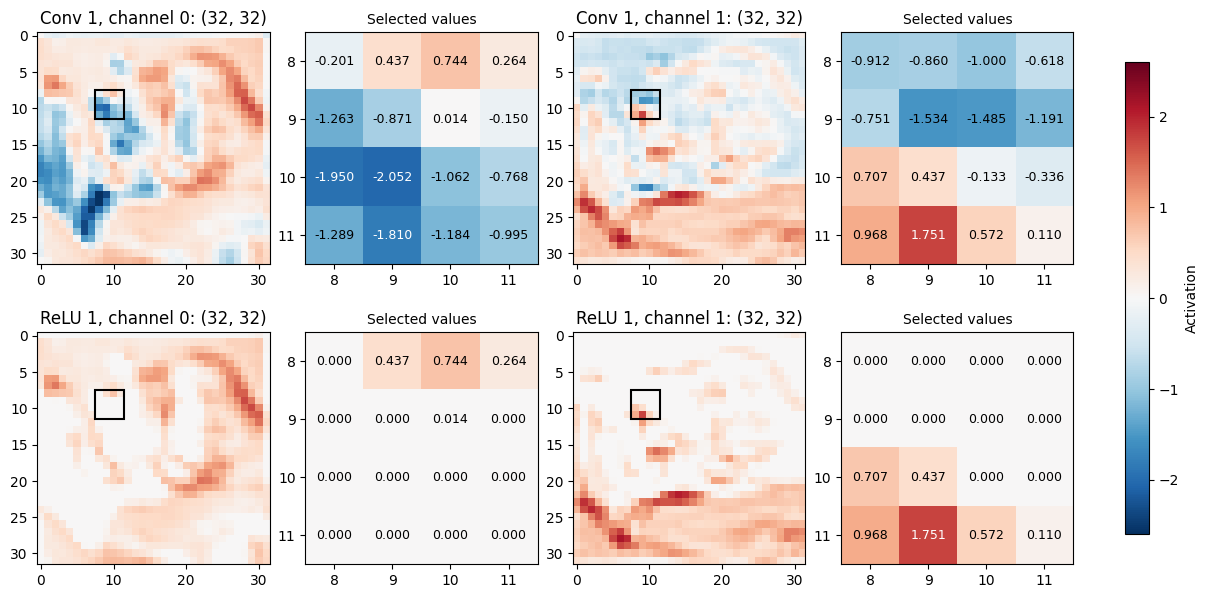

In [ ]:
# Берём изображение без случайных аугментаций.
image_index = 0
image, label = cifar_val[image_index]
model_device = next(model_baseline.parameters()).device

# Сохраняем режим каждого модуля и восстанавливаем его после просмотра.
original_modes = [(module, module.training) for module in model_baseline.modules()]
try:
    model_baseline.eval()
    with torch.no_grad():
        x = image.unsqueeze(0).to(model_device)
        activations = []
        for layer in feature_layers[:5]:
            x = layer(x)
            activations.append(x[0].detach().cpu().clone())
finally:
    for module, mode in original_modes:
        module.training = mode

conv1, relu1, conv2, relu2, pool = activations

# Обратная нормализация нужна только исходной фотографии.
mean = image.new_tensor([0.4914, 0.4822, 0.4465])[:, None, None]
std = image.new_tensor([0.247, 0.243, 0.261])[:, None, None]
rgb = (image * std + mean).clamp(0, 1)
plt.figure(figsize=(3, 3))
plt.imshow(rgb.permute(1, 2, 0).cpu(), interpolation="nearest")
plt.title(f"Input: {cifar_val.classes[label]}")
plt.axis("off")
plt.show()



def show_feature_maps(stages, names, channels, row=8, col=8, size=4):
    """Полная карта и её фрагмент с числами; общая шкала на всю фигуру."""
    limit = max(max(s[channels].abs().max().item() for s in stages), 1e-8)
    fig, axes = plt.subplots(len(stages), 2 * len(channels),
                             figsize=(6 * len(channels), 3 * len(stages)),
                             squeeze=False, constrained_layout=True)
    for r, (stage, name) in enumerate(zip(stages, names)):
        for c, channel in enumerate(channels):
            values = stage[channel]
            ax = axes[r, 2 * c]
            ax.imshow(values, cmap="RdBu_r", vmin=-limit, vmax=limit,
                      interpolation="nearest")
            ax.add_patch(Rectangle((col - 0.5, row - 0.5), size, size,
                                   fill=False, edgecolor="black", linewidth=1.5))
            ax.set_title(f"{name}, channel {channel}: {tuple(values.shape)}")
            crop = values[row:row + size, col:col + size]
            im = matrix_with_numbers(axes[r, 2 * c + 1], crop, "Selected values",
                                     vmin=-limit, vmax=limit, row0=row, col0=col)
    fig.colorbar(im, ax=axes.ravel().tolist(), label="Activation", shrink=0.8)
    plt.show()


show_feature_maps([conv1, relu1], ["Conv 1", "ReLU 1"], channels[:2])

#### 3. Откуда взялось одно число: считаем свёртку вручную

Многоканальная свёртка из [лекции 2, слайды 59–61](https://raw.githubusercontent.com/hse-ds/iad-deep-learning/master/2025/lectures/lecture02-convnets.pdf#page=59), в обозначениях PyTorch для ядра 3×3:

$$z_{kij}=b_k+\sum_{c=0}^{C_{\mathrm{in}}-1}\sum_{u=0}^{2}\sum_{v=0}^{2}
W_{kcuv}\,x_{c,i+u-1,j+v-1}.$$

$k$ — выходной канал; $c$ — входной. Bias прибавляем **один раз**, вне сумм. Здесь $C_{\mathrm{in}}=3$, шаг 1 и нулевая рамка шириной 1 (`padding='same'`). PyTorch не переворачивает ядро.

На входе нормированные пиксели: $x_c=(p_c-\mu_c)/\sigma_c$, $p_c\in[0,1]$; отрицательные значения допустимы.

Ниже: окно → веса → 27 произведений → сумма + bias → ReLU. Сверяем ручной результат с `Conv2d`, без округления при вычислениях.

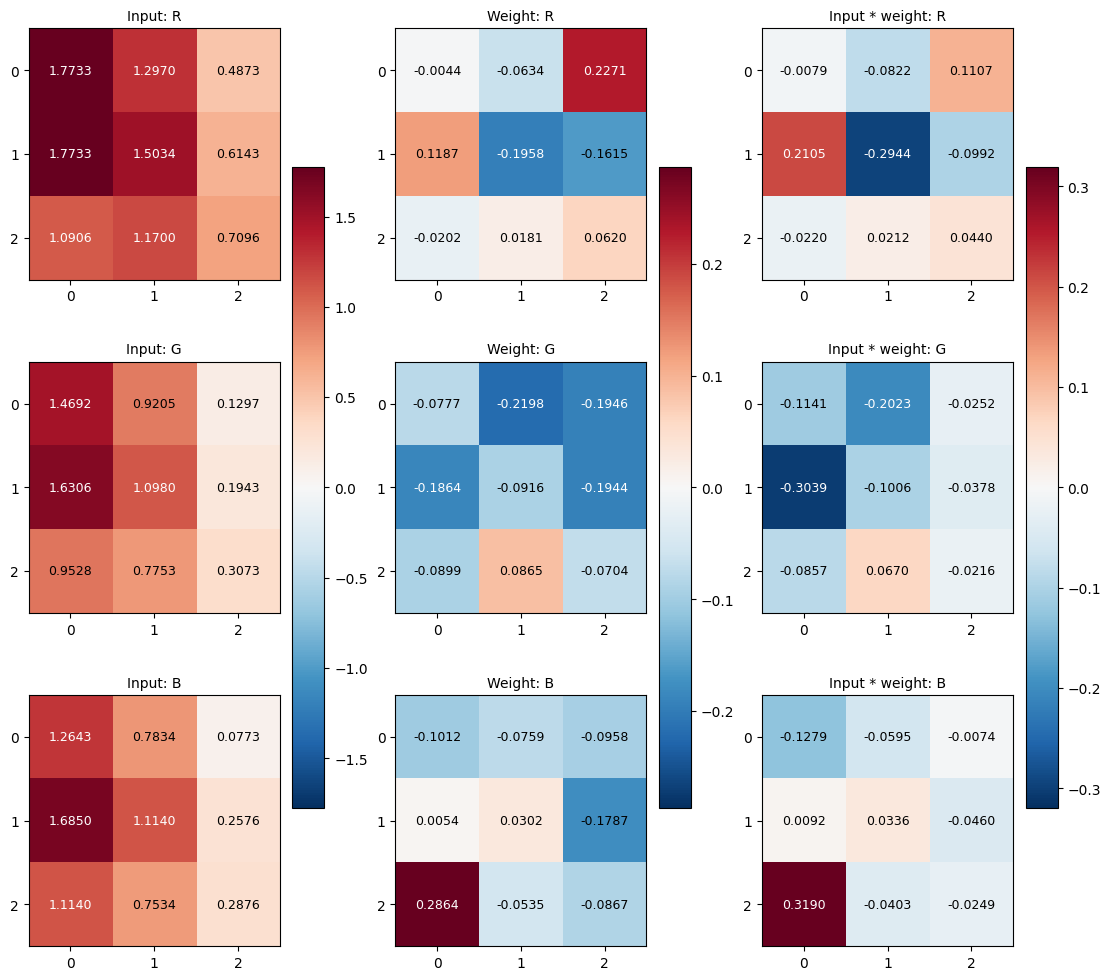

Сумма произведений по R: -0.119318
Сумма произведений по G: -0.824160
Сумма произведений по B: +0.055768
Сумма по каналам: -0.887710
Bias: -0.174210
Вручную: -1.061920; Conv2d: -1.061920
ReLU: max(0, -1.061920) = 0.000000


In [ ]:
channel, row, col = channels[0], 10, 10
padded = torch.nn.functional.pad(image.detach().cpu(), (1, 1, 1, 1))
patch = padded[:, row:row + 3, col:col + 3]
kernel = weights[channel]
products = patch * kernel

fig, axes = plt.subplots(3, 3, figsize=(11, 10), constrained_layout=True)
for column, (values, name) in enumerate([
    (patch, "Input"), (kernel, "Weight"), (products, "Input * weight")
]):
    limit = max(values.abs().max().item(), 1e-8)
    for c, color in enumerate(["R", "G", "B"]):
        im = matrix_with_numbers(axes[c, column], values[c], f"{name}: {color}",
                                 vmin=-limit, vmax=limit, fmt=".4f")
    fig.colorbar(im, ax=axes[:, column].tolist(), shrink=0.65)
plt.show()

contributions = products.sum(dim=(1, 2))
bias = feature_layers[0].bias[channel].detach().cpu()
manual = contributions.sum() + bias
actual = conv1[channel, row, col]
for color, value in zip(["R", "G", "B"], contributions):
    print(f"Сумма произведений по {color}: {value.item():+.6f}")
print(f"Сумма по каналам: {contributions.sum().item():+.6f}")
print(f"Bias: {bias.item():+.6f}")
print(f"Вручную: {manual.item():+.6f}; Conv2d: {actual.item():+.6f}")
print(f"ReLU: max(0, {actual.item():+.6f}) = {relu1[channel, row, col].item():.6f}")
# Расчёт идёт с полной точностью; подписи на рисунке округлены.
torch.testing.assert_close(manual, actual, rtol=1e-4, atol=1e-5)
torch.testing.assert_close(actual.clamp_min(0), relu1[channel, row, col])

#### 4. Вторая свёртка и pooling — тоже в числах

Вторая свёртка суммирует 16×3×3 произведений и bias. Одинаковый номер канала в разных слоях не означает одинаковый признак.

| Этап | Форма без батча | Рецептивное поле |
|---|---|---|
| Conv 1 → ReLU 1 | 16×32×32 | 3×3 |
| Conv 2 → ReLU 2 | 16×32×32 | 5×5 |
| MaxPool(2) | 16×16×16 | 6×6 |

Для свёрток 3×3 с шагом 1 после $\ell$ слоёв сторона поля равна $r_\ell=1+2\ell$ — запись закономерности из [лекции 3, слайды 13–15](https://raw.githubusercontent.com/hse-ds/iad-deep-learning/master/2025/lectures/lecture03-convnets.pdf#page=13). У границ часть поля приходится на padding.

MaxPool(2) с шагом 2 работает отдельно по каналам:
$$p_{kij}=\max_{u,v\in\{0,1\}} a_{k,2i+u,2j+v}.$$
Это формульная запись примера из [лекции 3, слайды 25–26](https://raw.githubusercontent.com/hse-ds/iad-deep-learning/master/2025/lectures/lecture03-convnets.pdf#page=25). Сравним карты Conv 2 и ReLU 2, затем фрагменты 4×4 до pooling и 2×2 после.

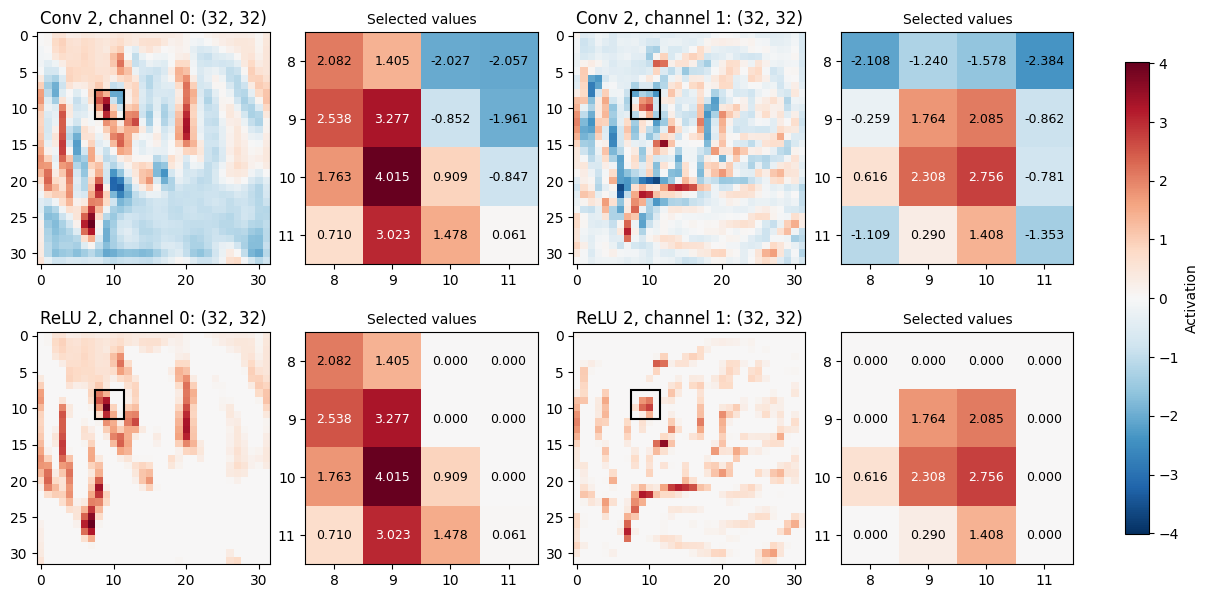

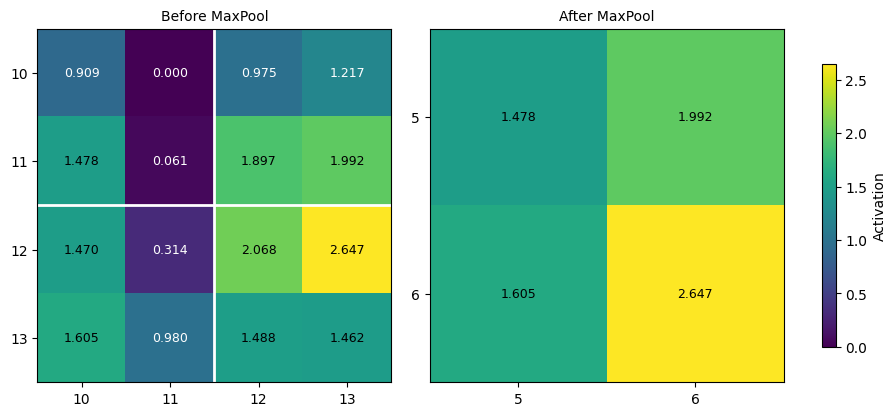

max([0.9089289307594299, 0.0, 1.4775484800338745, 0.06055999547243118]) = 1.477548
max([0.9753288626670837, 1.2165721654891968, 1.8965626955032349, 1.9918264150619507]) = 1.991826
max([1.4701296091079712, 0.3141224980354309, 1.6052154302597046, 0.9796146750450134]) = 1.605215
max([2.0681769847869873, 2.6472578048706055, 1.4879705905914307, 1.4620906114578247]) = 2.647258


In [ ]:
show_feature_maps([conv2, relu2], ["Conv 2", "ReLU 2"], channels[:2])
channel, row, col = channels[0], 5, 5
before = relu2[channel, 2 * row:2 * row + 4, 2 * col:2 * col + 4]
after = pool[channel, row:row + 2, col:col + 2]
limit = max(before.max().item(), 1e-8)
fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
im = matrix_with_numbers(axes[0], before, "Before MaxPool",
                         vmin=0, vmax=limit, cmap="viridis", row0=2*row, col0=2*col)
axes[0].axhline(1.5, color="white", linewidth=2)
axes[0].axvline(1.5, color="white", linewidth=2)
matrix_with_numbers(axes[1], after, "After MaxPool",
                    vmin=0, vmax=limit, cmap="viridis", row0=row, col0=col)
fig.colorbar(im, ax=axes.tolist(), label="Activation", shrink=0.8)
plt.show()
for i in range(2):
    for j in range(2):
        window = before[2*i:2*i+2, 2*j:2*j+2]
        print(f"max({window.flatten().tolist()}) = {after[i, j].item():.6f}")
        torch.testing.assert_close(window.max(), after[i, j])

### Куда смотрят свёртки

Сами веса обученных свёрток почти ничего не говорят о том, *почему* сеть выдала конкретный ответ. Полезнее спросить: **какие области входной картинки повлияли на предсказание класса $c$?** Один из самых популярных методов для этого — **Grad-CAM** ([Selvaraju et al., 2017](https://arxiv.org/abs/1610.02391)).

Идея:
1. Берём карты активаций $A^k$ последнего свёрточного слоя (после нелинейности, как в оригинальной статье) размера $h \times w$ ($k$ — номер канала). Они ещё сохраняют пространственную структуру, но уже содержат «высокоуровневые» признаки.
2. Считаем градиент логита класса $c$ по этим активациям: $\dfrac{\partial y^c}{\partial A^k_{ij}}$.
3. Усредняем градиент по пространству — получаем важность канала $k$ для класса $c$:
$$\alpha_k^c = \frac{1}{hw}\sum_{i,j} \frac{\partial y^c}{\partial A^k_{ij}}$$
4. Складываем карты с этими весами и оставляем только положительный вклад:
$$L^c_{\text{Grad-CAM}} = \mathrm{ReLU}\Big(\sum_k \alpha_k^c A^k\Big)$$
5. При необходимости карту $h \times w$ до размера входа и накладываем на картинку.

<!-- > **Замечание.** Усреднение градиента по пространству (шаг 3) естественно для сетей, где перед классификатором стоит global average pooling. У нас после свёрток идут `Flatten` + `Linear`, и у каждой пространственной позиции свои веса, так что здесь это эвристика. Есть варианты без усреднения, например HiResCAM, где градиент умножается на активации поэлементно. -->

Активация показывает отклик признака; **Grad-CAM связывает области изображения с выбранным классом**.

Здесь берём $A^k$ после второй ReLU (`feature_layers[3]`) и логит $y^c$ класса $c$ до softmax. Усредняем градиент по пространству, затем взвешиваем карты:

$$\alpha_k^c=\frac{1}{hw}\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}},
\qquad L^c_{ij}=\max\left(0,\sum_k\alpha_k^c A^k_{ij}\right).$$

Здесь 16 каналов и $h=w=32$.

<!-- Для показа делим $L^c$ на максимум; нулевую карту оставляем нулевой. Значения — **не вероятности**. Источник метода: [Selvaraju et al., Grad-CAM](https://arxiv.org/abs/1610.02391). -->

<!-- В отличие от MNIST-примера, наши свёртки имеют `padding='same'`, шаг 1, а целевой слой расположен до pooling. Карта уже 32×32 и не требует растяжения. Рецептивное поле 5×5 всё равно ограничивает точность локализации. -->

Пример для MNIST:
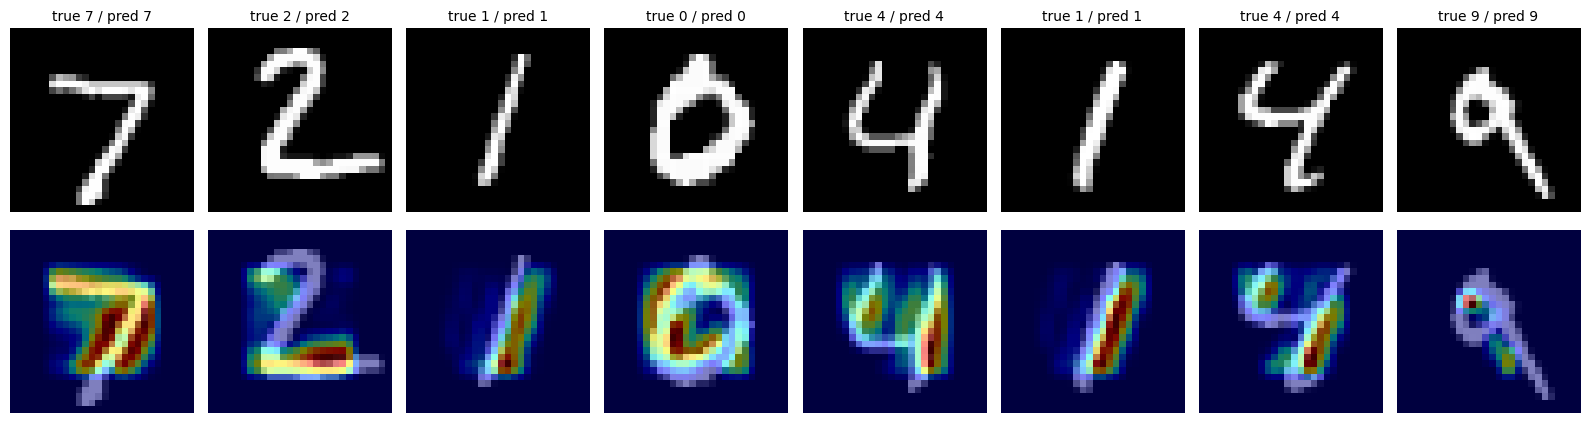

#### Достаём активации и градиенты

Forward hook сохраняет выход слоя, а [`torch.autograd.grad`](https://docs.pytorch.org/docs/stable/generated/torch.autograd.grad.html) вычисляет градиент логита по нему. Веса и накопленные градиенты параметров не меняются; хук снимается, прежний режим модели восстанавливается.

`eval()` меняет поведение Dropout/BatchNorm, но не отключает градиенты. Для Grad-CAM нужен граф вычислений, поэтому внутри включён `torch.enable_grad()`.

In [ ]:
class GradCAM:
    """Grad-CAM для слоёв baseline до pooling: карта совпадает с размером входа."""

    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer

    def __call__(self, x, target_class=None, normalize="per_map"):
        if normalize not in {"per_map", "joint"}:
            raise ValueError("normalize должен быть 'per_map' или 'joint'")
        if x.ndim != 4 or x.shape[0] == 0:
            raise ValueError("Нужен непустой батч [B, C, H, W]")
        modes = [(module, module.training) for module in self.model.modules()]
        saved = []
        handle = self.target_layer.register_forward_hook(
            lambda module, inputs, output: saved.append(output)
        )
        try:
            self.model.eval()
            with torch.enable_grad():
                x = x.detach().to(next(self.model.parameters()).device)
                x.requires_grad_(True)
                logits = self.model(x)
                if len(saved) != 1:
                    raise ValueError("Целевой слой должен вызываться ровно один раз")
                activations = saved[0]
                preds = logits.argmax(dim=1)
                if target_class is None:
                    targets = preds
                else:
                    targets = torch.as_tensor(target_class, device=logits.device,
                                              dtype=torch.long)
                    if targets.ndim == 0:
                        targets = targets.expand(x.shape[0])
                if targets.shape != preds.shape:
                    raise ValueError("Задайте один класс или по классу на картинку")
                score = logits.gather(1, targets[:, None]).sum()
                gradients, = torch.autograd.grad(score, activations)

            activations = activations.detach()
            gradients = gradients.detach()
            alpha = gradients.mean(dim=(2, 3), keepdim=True)
            raw = (alpha * activations).sum(dim=1).clamp_min(0)
            if raw.shape[-2:] != x.shape[-2:]:
                raise ValueError("Выберите ReLU до pooling в исходной baseline")
            scale = (raw.amax(dim=(1, 2), keepdim=True)
                     if normalize == "per_map" else raw.max())
            cam = raw / scale.clamp_min(torch.finfo(raw.dtype).tiny)
            result = dict(cam=cam, raw=raw, activations=activations,
                          gradients=gradients, alpha=alpha[:, :, 0, 0],
                          logits=logits, preds=preds, targets=targets)
            return {key: value.detach().cpu() for key, value in result.items()}
        finally:
            handle.remove()
            for module, training in modes:
                module.training = training


def cifar_rgb(image):
    image = image.detach().cpu()
    mean = image.new_tensor([0.4914, 0.4822, 0.4465])[:, None, None]
    std = image.new_tensor([0.247, 0.243, 0.261])[:, None, None]
    return (image * std + mean).clamp(0, 1).permute(1, 2, 0)


def show_gradcam(images, result, titles, n_cols=4):
    n = min(n_cols, len(images))
    if n == 0:
        return
    fig, axes = plt.subplots(3, n, figsize=(3.6*n, 10), squeeze=False,
                             constrained_layout=True)
    for i in range(n):
        rgb = cifar_rgb(images[i])
        axes[0, i].imshow(rgb)
        axes[0, i].set_title(titles[i], fontsize=9)
        axes[1, i].imshow(rgb)
        # Прозрачность 0.5 смешивает цвета с фотографией; шкала относится к CAM.
        im = axes[1, i].imshow(result["cam"][i], cmap="magma", alpha=0.5,
                                vmin=0, vmax=1, interpolation="nearest")
        axes[1, i].add_patch(Rectangle((11.5, 11.5), 4, 4, fill=False,
                                       edgecolor="cyan", linewidth=1.5))
        matrix_with_numbers(axes[2, i], result["cam"][i, 12:16, 12:16],
                            "CAM values: selected 4x4", cmap="magma",
                            vmin=0, vmax=1, row0=12, col0=12)
        axes[0, i].axis("off")
        axes[1, i].axis("off")
    # Непрозрачная шкала совпадает с числовыми фрагментами в нижнем ряду.
    fig.colorbar(axes[2, 0].images[0], ax=axes.ravel().tolist(),
                 label="Normalized Grad-CAM", shrink=0.6)
    plt.show()

#### Карты для предсказанного класса

Берём четыре изображения валидации без аугментаций. Ряды: оригинал → наложение Grad-CAM → выделенный фрагмент с числами. `per_map` делит каждую карту на собственный максимум: сравниваем расположение, а не величину откликов.

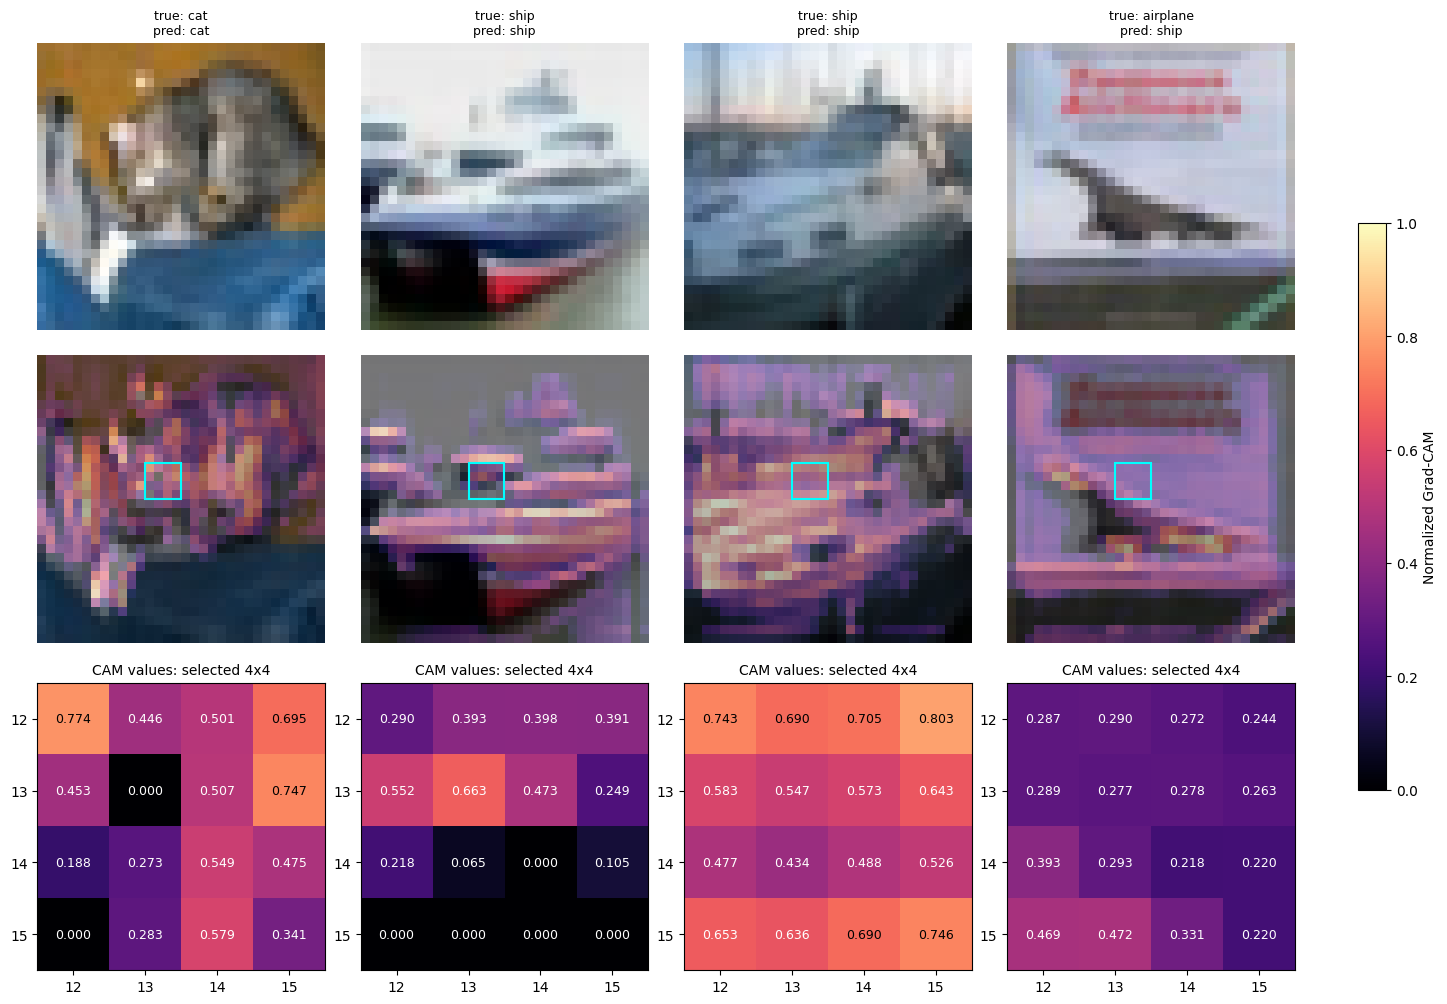

In [ ]:
gradcam = GradCAM(model_baseline, feature_layers[3])
indices = [0, 1, 2, 3]
x_cam = torch.stack([cifar_val[i][0] for i in indices])
y_cam = torch.tensor([cifar_val[i][1] for i in indices])
cam_result = gradcam(x_cam)
class_names = cifar_val.classes
titles = [f"true: {class_names[t]}\npred: {class_names[p]}"
          for t, p in zip(y_cam.tolist(), cam_result["preds"].tolist())]
show_gradcam(x_cam, cam_result, titles)

#### Из каких чисел получился Grad-CAM

Для максимума первой карты выводим по всем 16 каналам $\alpha_k$, $A^k_{ij}$ и произведение. Сумма → ReLU → деление на максимум воспроизводит значение карты.

$\alpha_k$ — средние градиенты для этой картинки и класса, не веса свёртки. Малые значения нормальны; максимум ненулевой карты после нормировки равен 1 по определению.

In [ ]:
r = cam_result
flat_index = int(r["raw"][0].argmax())
row, col = divmod(flat_index, r["raw"].shape[-1])
alpha = r["alpha"][0]
values = r["activations"][0, :, row, col]
contributions = alpha * values
print(f"Класс: {class_names[r['targets'][0].item()]}; позиция: ({row}, {col})")
print(" k    mean(gradient)        A[k,i,j]         alpha * A")
for k in range(len(alpha)):
    print(f"{k:2d}    {alpha[k].item():+.7e}    {values[k].item():+.7e}    "
          f"{contributions[k].item():+.7e}")
manual_raw = contributions.sum().clamp_min(0)
maximum = r["raw"][0].max()
manual_cam = manual_raw / maximum.clamp_min(torch.finfo(maximum.dtype).tiny)
print(f"Сумма: {contributions.sum().item():+.7e}")
print(f"После ReLU: {manual_raw.item():.7e}; максимум карты: {maximum.item():.7e}")
print(f"После нормировки: {manual_cam.item():.6f}")
print(f"Значение на карте: {r['cam'][0, row, col].item():.6f}")
if maximum == 0:
    print("Вся карта нулевая: положительной взвешенной суммы здесь нет.")
torch.testing.assert_close(manual_raw, r["raw"][0, row, col])
torch.testing.assert_close(manual_cam, r["cam"][0, row, col])

Класс: cat; позиция: (17, 5)
 k    mean(gradient)        A[k,i,j]         alpha * A
 0    +1.5928023e-03    +0.0000000e+00    +0.0000000e+00
 1    -1.1017154e-03    +0.0000000e+00    -0.0000000e+00
 2    +2.7272018e-04    +0.0000000e+00    +0.0000000e+00
 3    -1.8053162e-03    +1.5594743e-02    -2.8153443e-05
 4    +6.7186553e-04    +3.5687208e-01    +2.3977006e-04
 5    -5.3893414e-04    +0.0000000e+00    -0.0000000e+00
 6    -6.2183419e-05    +0.0000000e+00    -0.0000000e+00
 7    -1.0448788e-05    +0.0000000e+00    -0.0000000e+00
 8    +4.9106276e-04    +0.0000000e+00    +0.0000000e+00
 9    -7.8280900e-05    +0.0000000e+00    -0.0000000e+00
10    -3.6905170e-04    +0.0000000e+00    -0.0000000e+00
11    +2.0012683e-03    +3.4071853e+00    +6.8186922e-03
12    -1.8754727e-04    +0.0000000e+00    -0.0000000e+00
13    -5.2317593e-04    +6.5218073e-01    -3.4120525e-04
14    -2.7005075e-04    +0.0000000e+00    -0.0000000e+00
15    -7.6199952e-04    +0.0000000e+00    -0.0000000e+00
Сумм

#### Одна картинка — разные классы

Строим десять карт одной картинки. `joint` делит их на общий максимум: слабые карты сохраняют малую яркость. В заголовках — логиты.

Сравнивать можно величины Grad-CAM, но не уверенность модели. Предсказанный класс не обязан иметь самую яркую карту.

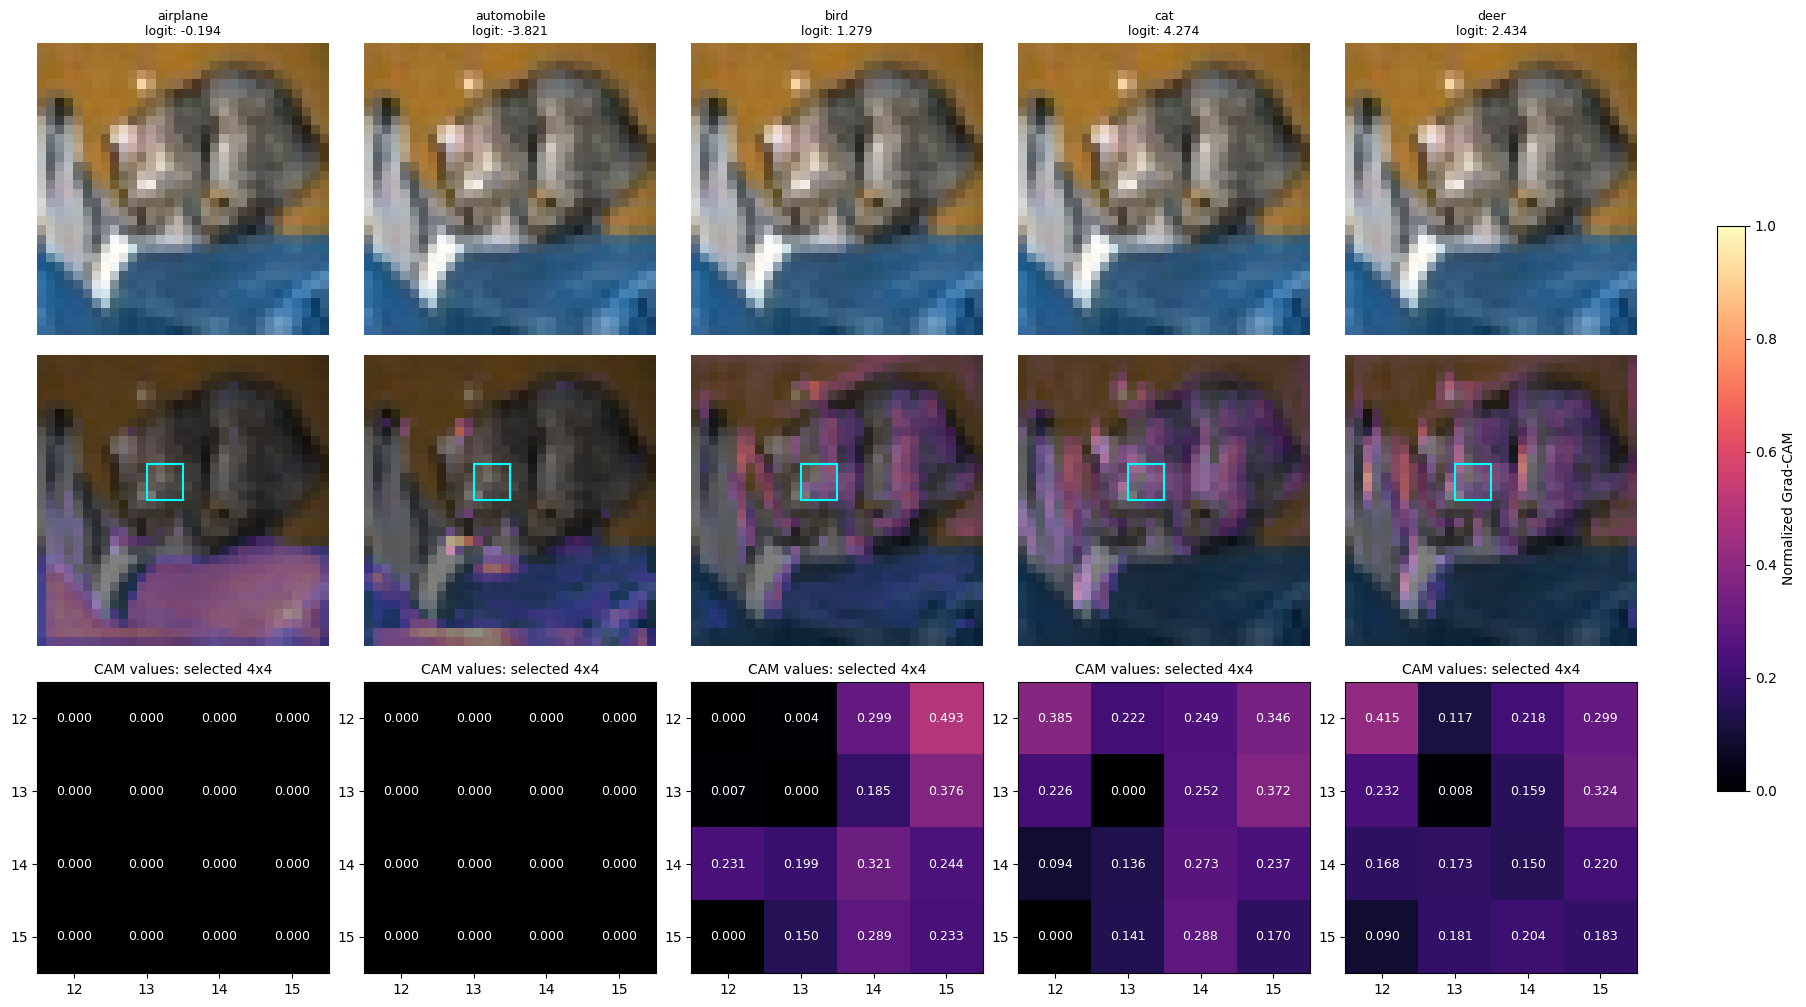

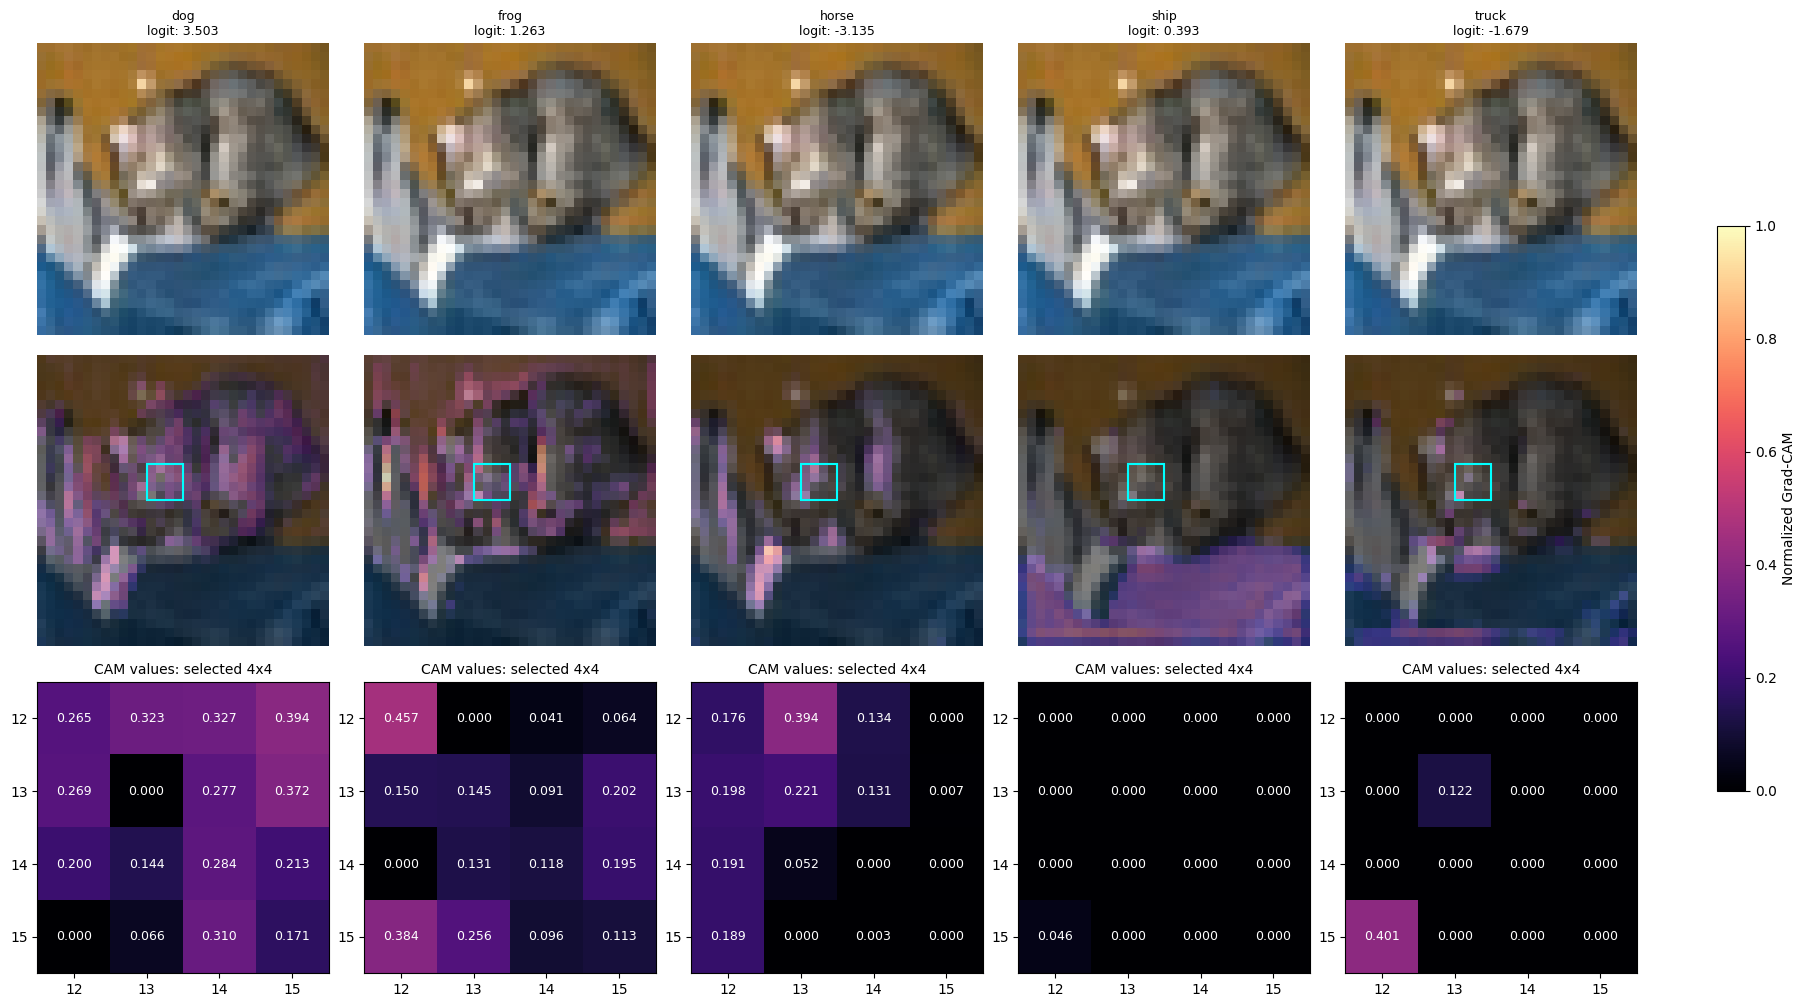

In [ ]:
x_all = x_cam[:1].repeat(10, 1, 1, 1)
all_classes = gradcam(x_all, target_class=torch.arange(10), normalize="joint")
for start in (0, 5):
    end = start + 5
    part = {key: value[start:end] for key, value in all_classes.items()}
    titles = [f"{class_names[c]}\nlogit: {all_classes['logits'][c, c].item():.3f}"
              for c in range(start, end)]
    show_gradcam(x_all[start:end], part, titles, n_cols=5)

#### Смотрим на ошибки

Для первых четырёх ошибок валидации сравним истинный и предсказанный классы на общей шкале. Подсветка фона — повод проверить гипотезу, не доказательство причины ошибки.

Предсказанный класс


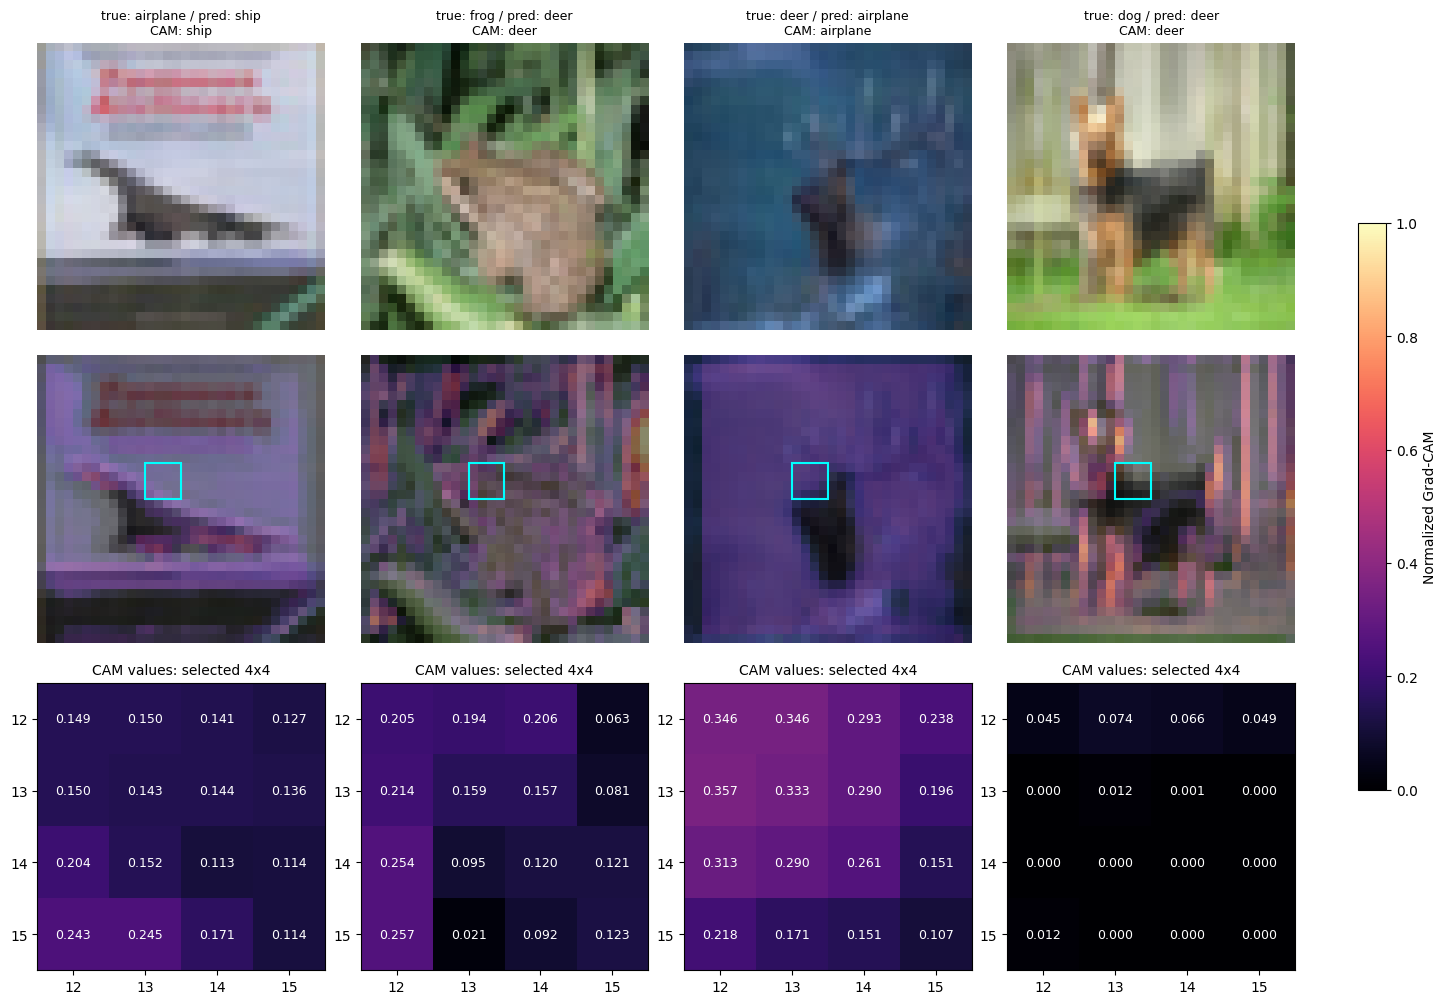

Истинный класс


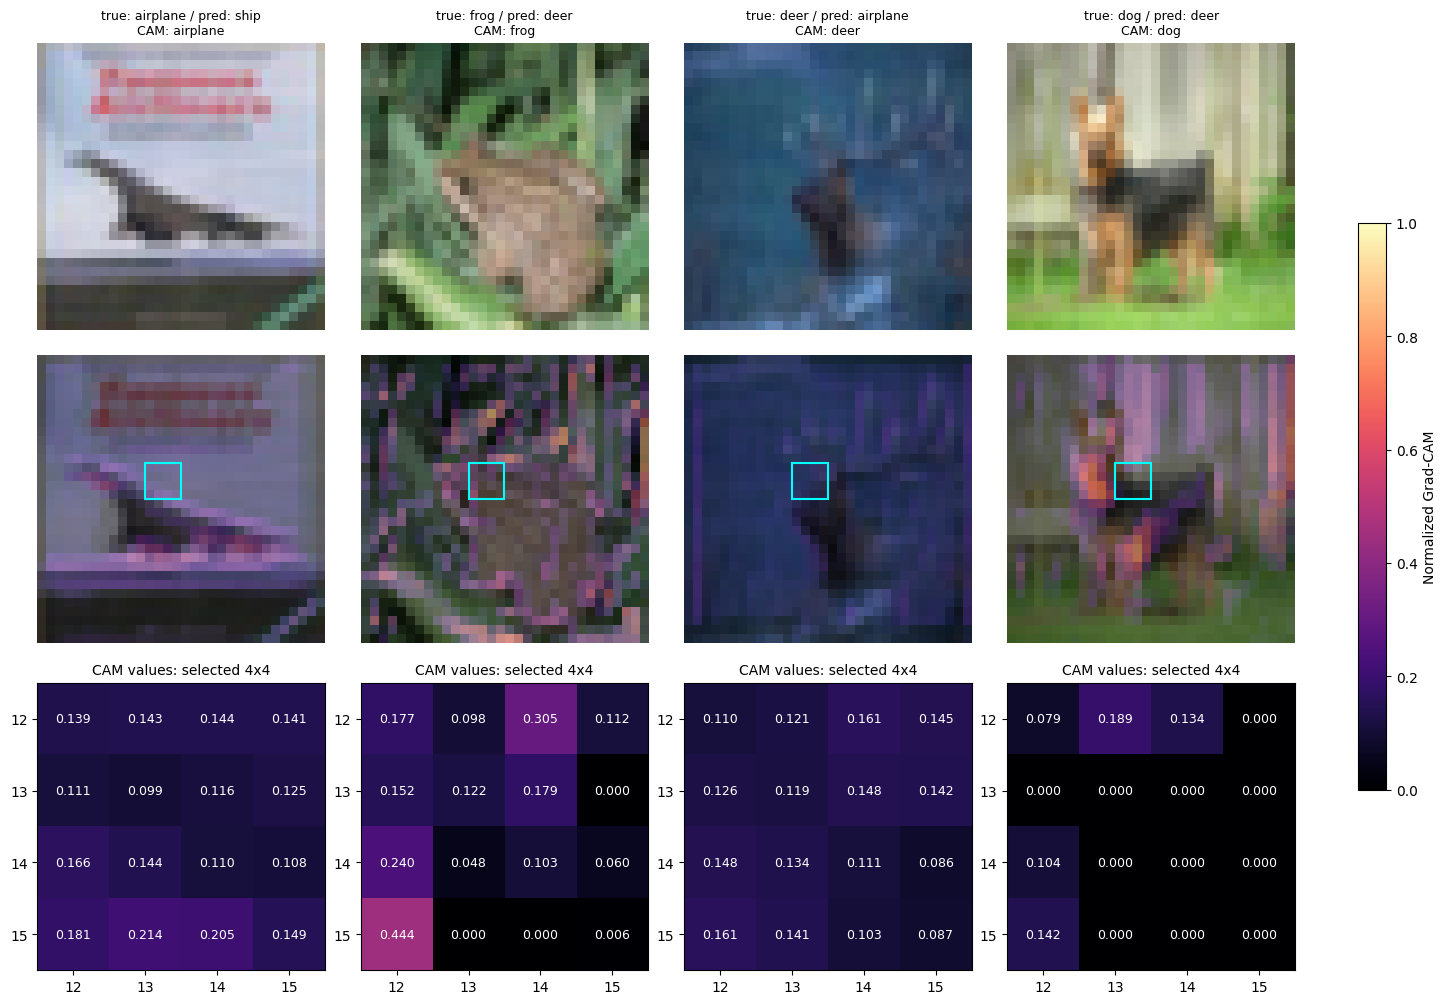

In [ ]:
wrong_images, wrong_labels = [], []
original_modes = [(module, module.training) for module in model_baseline.modules()]
model_device = next(model_baseline.parameters()).device
try:
    model_baseline.eval()
    with torch.no_grad():
        for batch_images, batch_labels in val_dataloader:
            preds = model_baseline(batch_images.to(model_device)).argmax(1).cpu()
            for index in (preds != batch_labels.cpu()).nonzero(as_tuple=True)[0]:
                wrong_images.append(batch_images[index].cpu())
                wrong_labels.append(int(batch_labels[index]))
                if len(wrong_images) == 4:
                    break
            if len(wrong_images) == 4:
                break
finally:
    for module, training in original_modes:
        module.training = training

if not wrong_images:
    print("На валидации ошибок не найдено.")
else:
    x_err = torch.stack(wrong_images)
    y_err = torch.tensor(wrong_labels)
    pred_result = gradcam(x_err)
    true_result = gradcam(x_err, target_class=y_err)
    # Одна шкала для обоих наборов, без повторного прямого прохода.
    common_max = torch.maximum(pred_result["raw"].max(), true_result["raw"].max())
    common_max = common_max.clamp_min(torch.finfo(common_max.dtype).tiny)
    for description, result in [("Предсказанный класс", pred_result),
                                 ("Истинный класс", true_result)]:
        result["cam"] = result["raw"] / common_max
        titles = [f"true: {class_names[t]} / pred: {class_names[p]}\n"
                  f"CAM: {class_names[c]}"
                  for t, p, c in zip(y_err.tolist(), pred_result["preds"].tolist(),
                                      result["targets"].tolist())]
        print(description)
        show_gradcam(x_err, result, titles)

#### Мини-эксперимент: первый или второй слой?

Для тех же картинок и классов построим Grad-CAM по первой ReLU (`feature_layers[1]`). Сравните расположение подсветки со второй ReLU.

Обе карты 32×32, но рецептивные поля 3×3 и 5×5. В глубоких сетях поздние признаки охватывают больше входа, а карты часто меньше. Здесь нормировка отдельная для каждой карты: яркость разных слоёв напрямую не сравниваем.

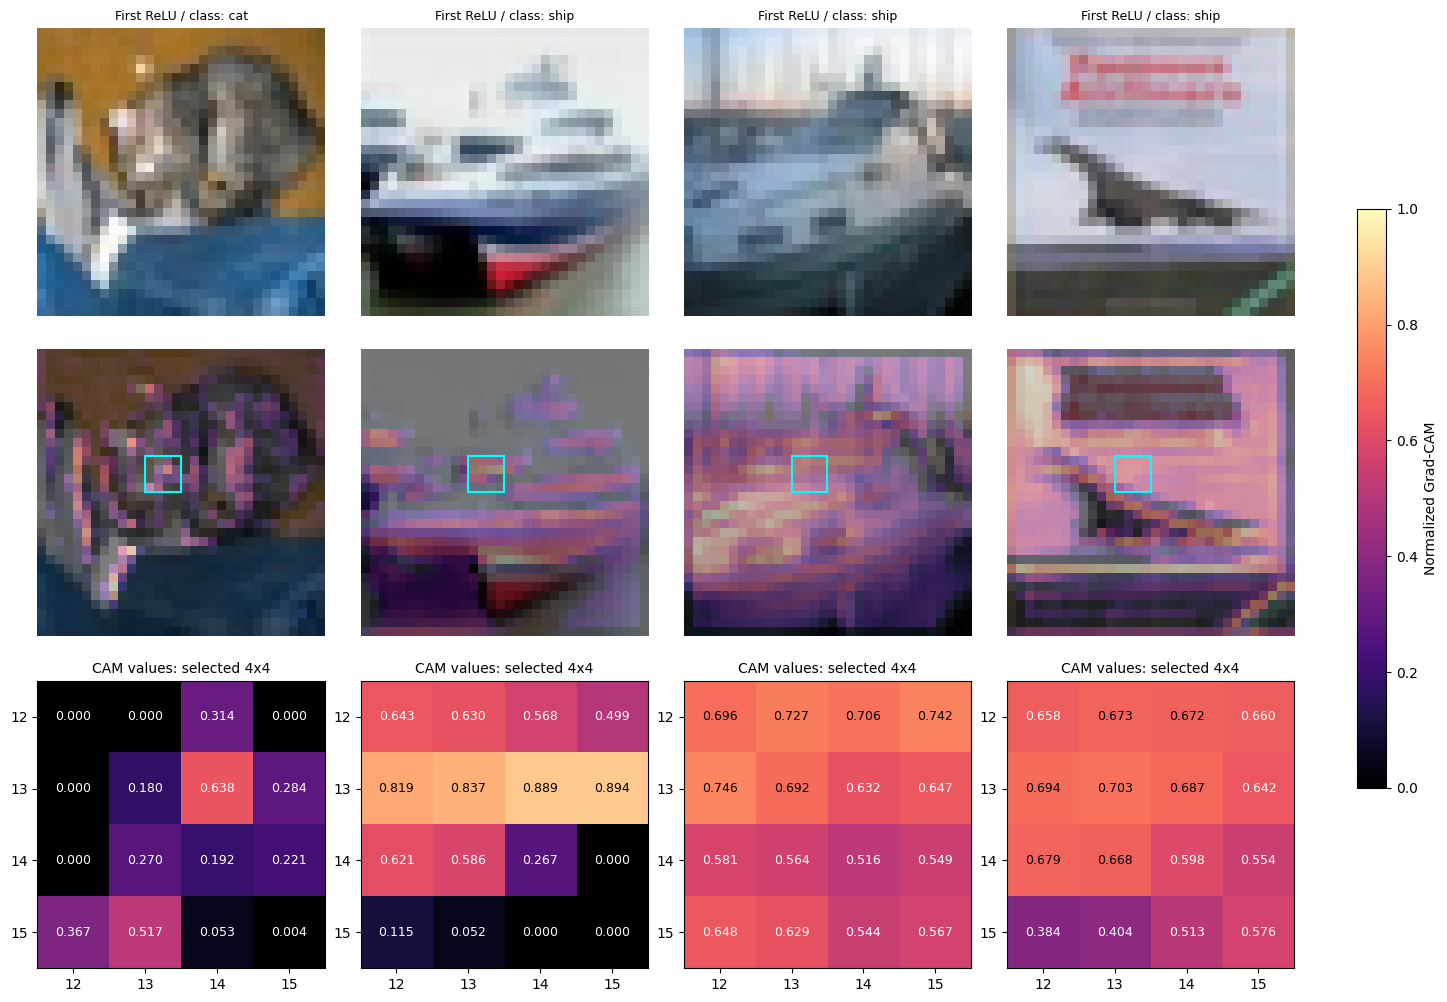

In [ ]:
# Меняйте image indices выше, чтобы проверить наблюдения на других примерах.
gradcam_first = GradCAM(model_baseline, feature_layers[1])
first_result = gradcam_first(x_cam, target_class=cam_result["preds"])
titles = [f"First ReLU / class: {class_names[c]}"
          for c in first_result["targets"].tolist()]
show_gradcam(x_cam, first_result, titles)

#### Как читать результаты

- **Веса** — параметры; **активации** — отклики на картинку; **Grad-CAM** — приближённое объяснение для класса.
- Смотрите на colorbar: шкалы между фигурами могут отличаться. Денормализуем только исходную фотографию.
- Усреднение градиентов теряет различия между позициями, особенно существенные при `Flatten → Linear`. Grad-CAM не является сегментацией или доказательством причинности.
- Нулевая карта означает отсутствие положительной взвешенной суммы, а не отсутствие использования изображения. Карты необученной сети тоже не стоит считать выученными признаками.

**Обсудите:** что обнуляет ReLU? Почему pooling сохраняет число каналов? Почему смена целевого класса меняет Grad-CAM при тех же весах и входе?

### Задание 2. Активации

Поэкспериментируйте с функциями активации сети. Попробуйте заменить ReLU на LeakyReLU, ELU или SELU. Как замена влияет на качество и скорость сходимости?

Почитать про разные функции активации можно [здесь](https://ml-explained.com/blog/activation-functions-explained) и в [документации PyTorch](https://pytorch.org/docs/stable/nn.html#non-linear-activations-weighted-sum-nonlinearity).

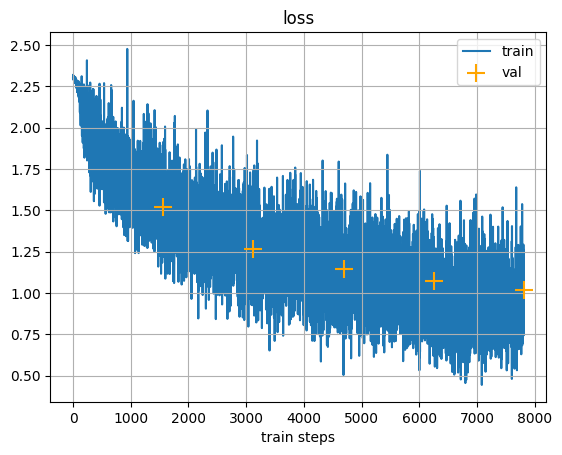

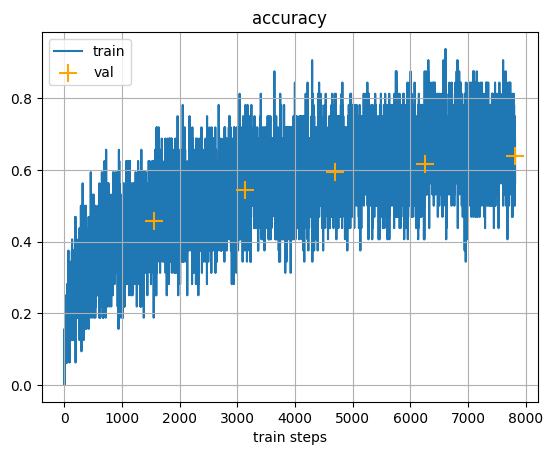

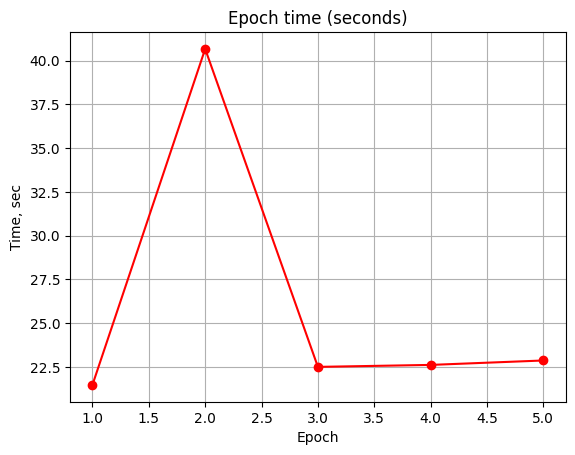

Epoch 5/5
Train loss: 0.942098
Train acc: 0.668340
Val loss: 1.016810
Val acc: 0.638400
Epoch time: 22.86 sec


{'train_loss': [2.3053083419799805,
  2.319570541381836,
  2.3069961071014404,
  2.307814359664917,
  2.289734363555908,
  2.3094027042388916,
  2.312938690185547,
  2.3075475692749023,
  2.3001956939697266,
  2.3123228549957275,
  2.3047072887420654,
  2.2929649353027344,
  2.3095011711120605,
  2.29836368560791,
  2.310685157775879,
  2.2967307567596436,
  2.2982845306396484,
  2.2948007583618164,
  2.2935171127319336,
  2.286417245864868,
  2.2911572456359863,
  2.2883973121643066,
  2.298670530319214,
  2.282136917114258,
  2.30319881439209,
  2.278872489929199,
  2.287111759185791,
  2.290496349334717,
  2.2837953567504883,
  2.296431064605713,
  2.2993459701538086,
  2.294727325439453,
  2.276984453201294,
  2.3030714988708496,
  2.303551197052002,
  2.273074150085449,
  2.2815065383911133,
  2.284231662750244,
  2.280447244644165,
  2.269082546234131,
  2.30544376373291,
  2.2706100940704346,
  2.2774808406829834,
  2.28023624420166,
  2.2846713066101074,
  2.2919087409973145,
 

In [ ]:
class ModelBaseline(nn.Module):
    def __init__(self, activation = nn.ReLU):

        super(ModelBaseline, self).__init__()

        self.model = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size= (3, 3), padding='same'),
            activation(),
            nn.Conv2d(in_channels=16, out_channels=16, kernel_size= (3, 3), padding='same'),
            activation(),
            nn.MaxPool2d(kernel_size=(2, 2), stride=2),
            nn.Flatten(),
            nn.Linear(in_features=16 * 16 * 16, out_features=128),
            activation(),
            nn.Linear(in_features=128, out_features=10)
        )

    def forward(self, x):
        return self.model(x)

train_dataloader = torch.utils.data.DataLoader(
    cifar_train, batch_size=32, shuffle=True, num_workers=4
)
val_dataloader = torch.utils.data.DataLoader(
    cifar_val, batch_size=32, shuffle=False, num_workers=4
)

model_baseline2 = ModelBaseline(activation=nn.LeakyReLU).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model_baseline2.parameters(), lr=0.001, momentum=0.9)

train(model_baseline2, criterion, optimizer, train_dataloader, val_dataloader)

## 2. Аугментации

Аугментация данных - очень мощный процесс, который позволяет увеличить количество тренировочных данных. С помощью поворотов, отражения, добавления шума, сдвигов и других преобразований, картинка немного меняется, однако сохраняет свою прежнюю метку. С помощью функции Compose можно объединять несколько трансформаций изображения, а потом применять их при чтении датасета. Полный список аугментаций доступен [тут](https://pytorch.org/vision/stable/transforms.html). Изучите его и поэкспериментируйте с различными трансформациями изображения.

Довольно мощным и эффективным инструментом для аугментаций на картинках является библиотека `albumentations`. В этом курсе мы не будем её рассматривать, но можете поэкспериментировать с ней сами.

In [ ]:
import PIL

transform = transforms.Compose(
    [
        transforms.ColorJitter(hue=0.05, saturation=0.05),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(20),
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261)),
    ]
)

base_transform = torchvision.transforms.Compose(
    [
        torchvision.transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261)),
    ]
)

cifar_train = torchvision.datasets.CIFAR10(
    root="./cifar", train=True, download=True, transform=transform
)
cifar_val = torchvision.datasets.CIFAR10(
    root="./cifar", train=False, download=True, transform=base_transform
)

train_dataloader = torch.utils.data.DataLoader(
    cifar_train, batch_size=32, shuffle=True, num_workers=4
)
val_dataloader = torch.utils.data.DataLoader(
    cifar_val, batch_size=32, shuffle=False, num_workers=4
)

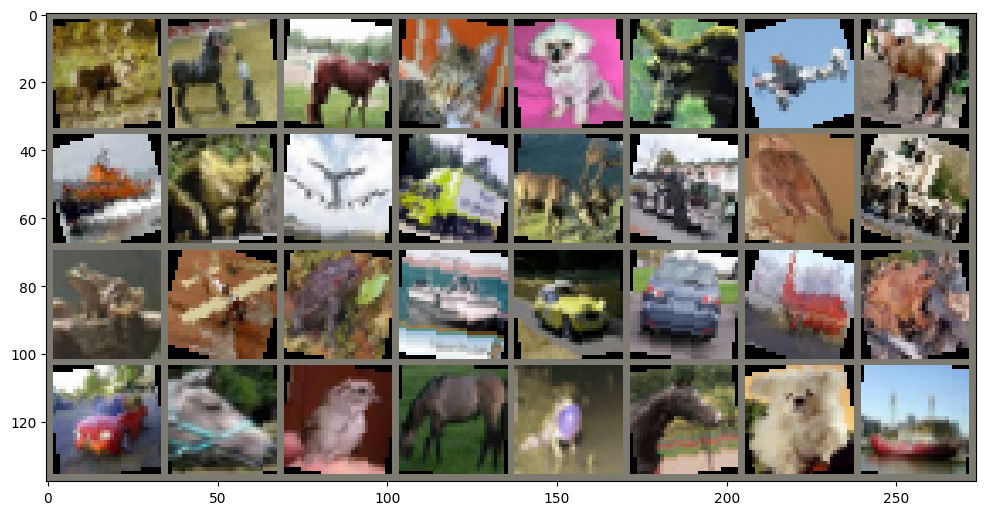

In [ ]:
images, labels = next(iter(train_dataloader))

plt.figure(figsize=(12, 12))
# create grid of images
img_grid = torchvision.utils.make_grid(images)
# show images
matplotlib_imshow(img_grid, one_channel=False)

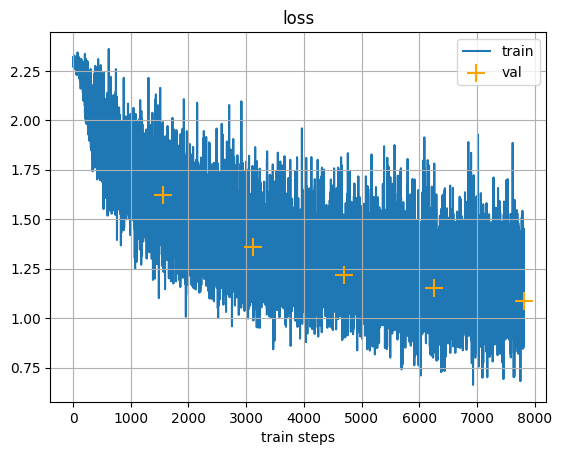

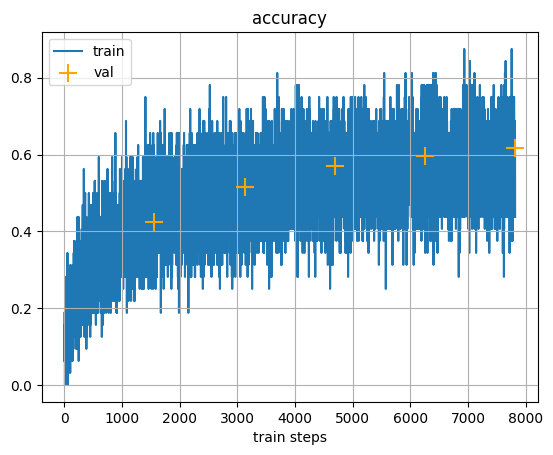

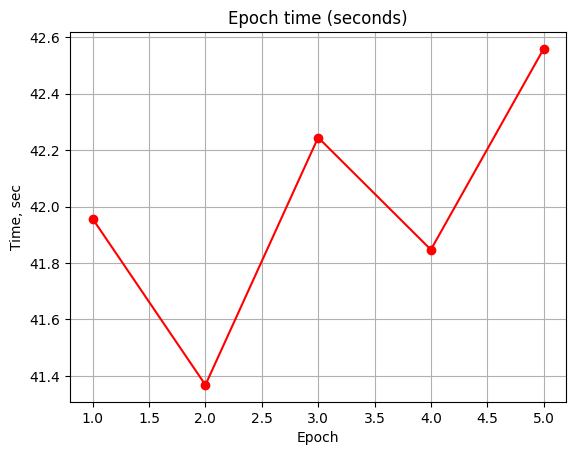

Epoch 5/5
Train loss: 1.183538
Train acc: 0.578900
Val loss: 1.084677
Val acc: 0.616700
Epoch time: 42.56 sec


In [ ]:
model_baseline = ModelBaseline().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model_baseline.parameters(), lr=0.001, momentum=0.9)

train(model_baseline, criterion, optimizer, train_dataloader, val_dataloader);

## 3. Регуляризации и нормализации в нейронных сетях

### Dropout
Если сеть имеет сложную архитектуру, то возможно переобучение - процесс, в котором модель слишком сильно подстраивается под тренировочную выборку и потом дает заниженное качество на тестовой. Для борьбы с этим можно использовать Dropout. Идея метода очень проста. На тренировке `torch.nn.Dropout` зануляет каждый элемент входного тензора с вероятностью $p$. На инференсе ничего не зануляется, но, для того, чтобы сохранить масштаб выходов сети, все элементы входного тензора делятся на $1 - p$.

$$d(x)=\begin{cases}
\dfrac{m\odot x}{1-p},\quad m_i\sim\operatorname{Bernoulli}(1-p), & \text{обучение},\\
x, & \text{применение}.
\end{cases}$$

![Dropout](https://github.com/hse-ds/iad-deep-learning/blob/master/2022/seminars/sem03/static/dropout.png?raw=1)

Для стабилизации и ускорения сходимости обучения часто используют батч нормализацию. В **PyTorch** она тоже имплементирована в виде слоя — [`torch.nn.BatchNorm2d`](https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html). Обычно батч нормализацию вставляют между смысловыми блоками нейронной сети, чтобы сохранять распределение данных на всём forward pass. Обратите внимание, что на тренировке выборочные среднее и стандартное отклонение каждый раз заново вычисляются по батчу, а также у слоя есть обучаемых два числовых параметра на каждый канал входного тензора. На инференсе в качестве среднего и дисперсии используются оценки, полученные скользящими средними во время тренировки.

![Batch Norm](https://github.com/hse-ds/iad-deep-learning/blob/master/2022/seminars/sem03/static/batch_norm.png?raw=1)

В `BatchNorm2d` статистики считают отдельно по каналам, по всем $M=BHW$ элементам батча и пространственным позициям:

$$\mu_c=\frac1M\sum_{b,i,j}x_{bcij},\qquad
\sigma_c^2=\frac1M\sum_{b,i,j}(x_{bcij}-\mu_c)^2,$$
$$z_{bcij}=\gamma_c\frac{x_{bcij}-\mu_c}{\sqrt{\sigma_c^2+\varepsilon}}+\beta_c.$$

$\gamma_c$ и $\beta_c$ — два обучаемых параметра на канал. При обучении используются статистики батча, при применении — накопленные скользящие оценки (при стандартном `track_running_stats=True`). Слой обычно ставят между свёрткой и активацией; он может облегчать оптимизацию, но не фиксирует всё распределение признаков.

Это адаптация формул из [лекции 4, слайды 37–42](https://raw.githubusercontent.com/hse-ds/iad-deep-learning/master/2025/lectures/lecture04-optimization-convnets.pdf#page=37) к тензору `B×C×H×W`. Детали реализации: [PyTorch BatchNorm2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html).

Давайте обучим новую сеть, в которой будет 3 VGG блока и добавим в неё батч нормализацию и дропаут.


In [ ]:
model = nn.Sequential(
    nn.Conv2d(3, 16, 3, padding=1),
    nn.BatchNorm2d(16),
    nn.ReLU(),
    nn.Conv2d(16, 16, 3, padding=1),
    nn.BatchNorm2d(16),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),
    # nn.Dropout(0.2),
    nn.Conv2d(16, 32, 3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.Conv2d(32, 32, 3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),
    # nn.Dropout(0.2),
    nn.Conv2d(32, 64, 3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.Conv2d(64, 64, 3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),
    # nn.Dropout(0.2),
    nn.Flatten(),
    nn.Linear(64 * 4 * 4, 128),
    nn.BatchNorm1d(128),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(128, 10),
)

In [ ]:
model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

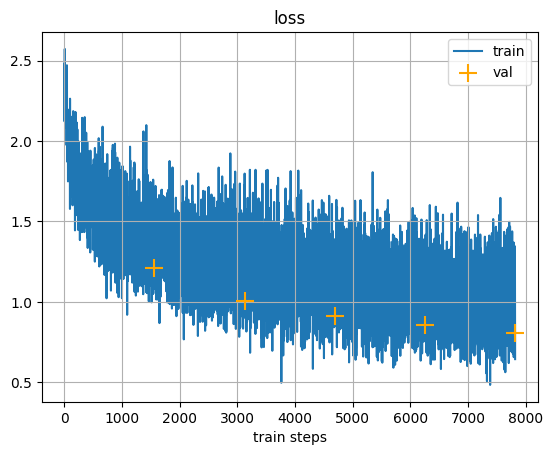

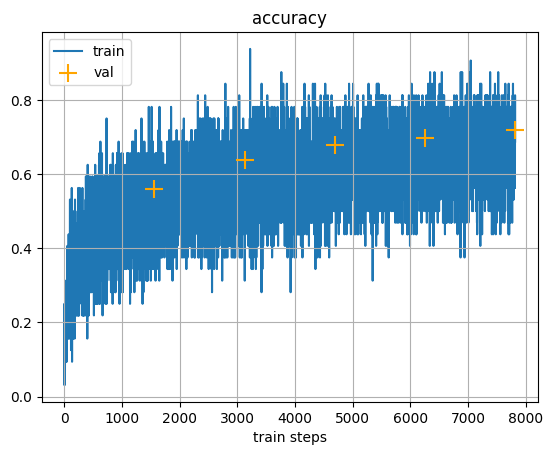

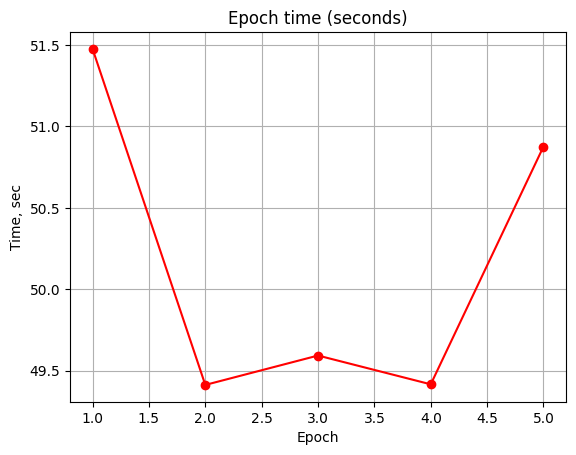

Epoch 5/5
Train loss: 0.993595
Train acc: 0.652420
Val loss: 0.808683
Val acc: 0.719000
Epoch time: 50.88 sec


In [ ]:
train(model, criterion, optimizer, train_dataloader, val_dataloader);

### Задание 1. Реализация Spatial Dropout

Обычный Dropout зануляет отдельные нейроны, но при использовании свёрток мы бы хотели пойти дальше и занулять целые каналы (почему?). Реализуйте Spatial Dropout, который позволит это сделать.

In [ ]:
class SpatialDropout(nn.Module):
    def __init__(self, p=0.2):
        super(SpatialDropout, self).__init__()
        self.p = p

    def forward(self, x):
        if not self.training or self.p == 0.0:
            # в режиме eval() или p= 0 возвращаем как есть
            return x

        # x имеет форму [N, C, H, W]
        N, C, H, W = x.shape

        # Создаём маску: какие каналы обнуляем
        # Берём для каждой картинки в батче случайный вектор длины C
        # shape: [N, C, 1, 1] -> потом будет broadcast на H и W
        mask = (torch.rand(N, C, 1, 1, device=x.device, dtype=x.dtype) > self.p).float()

        # Чтобы сохранять ожидаемое значение (как и в обычном Dropout),
        # оставшиеся каналы умножаем на масштаб 1/(1-p).
        return x * mask / (1.0 - self.p)

In [ ]:
model = nn.Sequential(
    nn.Conv2d(3, 16, 3, padding=1),
    nn.BatchNorm2d(16),
    nn.ReLU(),
    nn.Conv2d(16, 16, 3, padding=1),
    nn.BatchNorm2d(16),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),
    SpatialDropout(0.2),   # Вот тут!

    nn.Conv2d(16, 32, 3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.Conv2d(32, 32, 3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),
    SpatialDropout(0.3),   # Ещё один, чуть сильнее

    nn.Conv2d(32, 64, 3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.Conv2d(64, 64, 3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),
    SpatialDropout(0.4),   # Можно добавлять глубже

    nn.Flatten(),
    nn.Linear(64 * 4 * 4, 128),
    nn.BatchNorm1d(128),
    nn.ReLU(),
    nn.Dropout(0.5),  # здесь оставляем обычный Dropout для полносвязных
    nn.Linear(128, 10),
)

In [ ]:
model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

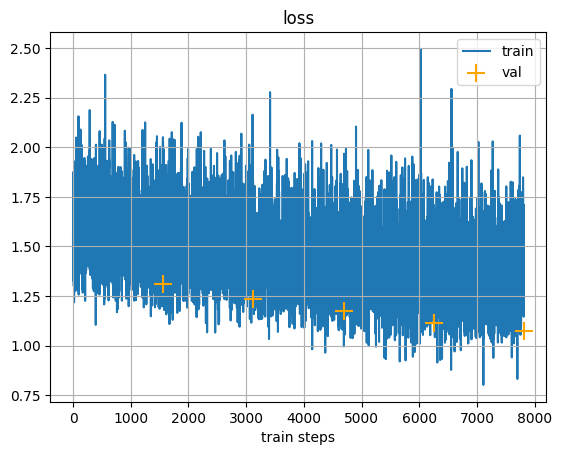

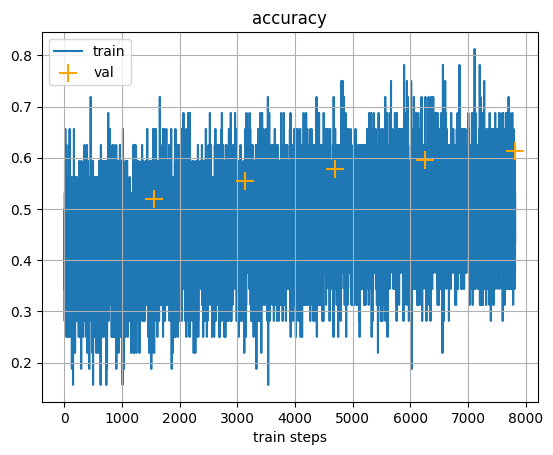

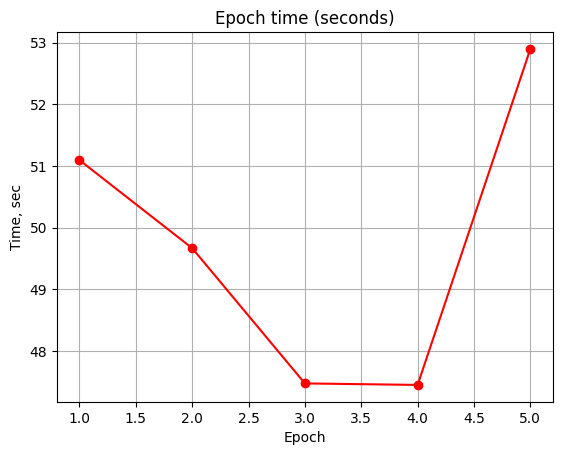

Epoch 5/5
Train loss: 1.372227
Train acc: 0.506500
Val loss: 1.074997
Val acc: 0.612600
Epoch time: 52.90 sec


In [ ]:
train(model, criterion, optimizer, train_dataloader, val_dataloader, n_epochs = 5);